# Activité Pratique N°2 — Modèles génératifs avec PyTorch

- **Enseignant :** Mohamed YOUSSFI
- **Matière :** IA Générative
- **Nom :** À compléter
- **Prénom :** À compléter
- **Groupe :** À compléter
- **Année universitaire :** 2026–2027

Ce notebook réalise la première partie de l'activité pratique : un modèle discriminatif, un autoencodeur classique et un autoencodeur variationnel (VAE), entraînés sur le jeu MNIST avec PyTorch.

Les architectures, les fonctions de perte et les nombres d'époques suivent le notebook de cours. Les parties GAN et modèles de diffusion de ce support ne sont pas traitées ici.

Le fil du travail est le suivant :

$$
\text{Reconnaître} \rightarrow \text{Représenter} \rightarrow \text{Reconstruire} \rightarrow \text{Générer}
$$

## 1. Introduction et objectifs

### Deux questions différentes

Un modèle **discriminatif** apprend à répondre à la question : « quelle est la classe de cette image ? ». Sur MNIST, il approxime

$$
P(y \mid x)
$$

où \(x\) est l'image et \(y\) le chiffre.

Un modèle **génératif** s'intéresse à la façon dont les images elles-mêmes sont distribuées. Il cherche une représentation de

$$
P(x)
$$

ou, dans le cas du VAE, d'un modèle à variable latente \(P(x, z) = P(z)\,P(x \mid z)\). Cette différence d'objectif explique pourquoi un classifieur ne produit pas d'image, alors qu'un VAE peut décoder un vecteur tiré au hasard.

### Ce que ce notebook démontre

1. **Classification.** Un réseau entièrement connecté reconnaît le chiffre écrit dans une image.
2. **Reconstruction.** Un autoencodeur compresse l'image dans un code latent, puis la reconstruit.
3. **Génération.** Un VAE régularise cet espace latent pour pouvoir créer de nouvelles images, explorer une grille et interpoler entre deux chiffres.

Les trois modèles sont entraînés puis évalués sur les **10 000 images de test** de MNIST. Les graphiques et les poids affichés plus bas proviennent de cette exécution.

## 2. Configuration de l'environnement

Le projet est géré avec **uv** et un environnement virtuel Python 3.11. Le notebook s'exécute dans cet environnement : les bibliothèques ne sont pas installées globalement.

Le périphérique de calcul est choisi automatiquement. **CUDA** est utilisé s'il est disponible. Sinon, l'entraînement se fait sur **CPU**, ce qui est le cas prévu pour ce TP.

Les chemins sont résolus à partir de la racine du projet, même si le noyau Jupyter a pour répertoire courant le dossier `notebooks/`.

In [1]:
%matplotlib inline
import warnings
warnings.filterwarnings(
    "ignore",
    message="`torch.jit.script` is deprecated",
    category=FutureWarning,
)

import json
import math
import random
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision
import torcheval
from sklearn.metrics import (
    confusion_matrix,
    precision_recall_fscore_support,
    silhouette_score,
)
from torch.utils.data import DataLoader
from torchvision import datasets, transforms
import tqdm

SEED = 42
BATCH_SIZE = 128
LATENT_DIM = 2
EPOCHS_CLASSIFIER = 3
EPOCHS_AUTOENCODER = 5
EPOCHS_VAE = 20
BETA = 1.0


def reseed(seed=SEED):
    """Fixe les graines Python, NumPy et PyTorch."""
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)


reseed(SEED)

cwd = Path.cwd().resolve()
if (cwd / "pyproject.toml").exists():
    PROJECT_ROOT = cwd
elif (cwd.parent / "pyproject.toml").exists():
    PROJECT_ROOT = cwd.parent
else:
    raise RuntimeError(
        "Lancez le notebook depuis la racine du projet ou depuis notebooks/."
    )

DATA_DIR = PROJECT_ROOT / "data"
MODELS_DIR = PROJECT_ROOT / "models"
RESULTS_DIR = PROJECT_ROOT / "results"
for directory in (
    DATA_DIR,
    MODELS_DIR,
    RESULTS_DIR / "classifier",
    RESULTS_DIR / "autoencoder",
    RESULTS_DIR / "vae",
):
    directory.mkdir(parents=True, exist_ok=True)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Racine du projet :", PROJECT_ROOT)
print("PyTorch           :", torch.__version__)
print("TorchVision       :", torchvision.__version__)
print("TorchEval         :", torcheval.__version__)
print("NumPy             :", np.__version__)
print("Matplotlib        :", plt.matplotlib.__version__)
print("tqdm              :", tqdm.__version__)
print("Périphérique      :", device)

plt.rcParams.update(
    {
        "figure.dpi": 110,
        "savefig.dpi": 140,
        "font.size": 11,
        "axes.titlesize": 13,
        "axes.labelsize": 11,
        "axes.unicode_minus": False,
    }
)


def save_figure(fig, relative_path):
    """Enregistre une figure dans results/ et confirme le chemin."""
    path = RESULTS_DIR / relative_path
    path.parent.mkdir(parents=True, exist_ok=True)
    fig.savefig(path, dpi=140, bbox_inches="tight")
    print(f"Figure enregistrée : {path}")
    return path


def label_row(axis, text):
    """Nomme une ligne d'images même lorsque les axes sont masqués."""
    axis.text(
        -0.18,
        0.5,
        text,
        transform=axis.transAxes,
        rotation=90,
        va="center",
        ha="right",
        fontsize=8,
        clip_on=False,
    )

Racine du projet : C:\Users\amald\Desktop\TP_ai_générative_N2
PyTorch           : 2.15.0+cpu
TorchVision       : 0.29.2+cpu
TorchEval         : 0.0.7
NumPy             : 2.4.6
Matplotlib        : 3.11.2
tqdm              : 4.70.1
Périphérique      : cpu


### Lecture des versions

La cellule précédente confirme que PyTorch, TorchVision et TorchEval s'importent dans le même interpréteur. Le périphérique affiché est celui qui sera utilisé pour tous les tenseurs et tous les modèles. Les graines aléatoires sont fixées à 42 afin de rendre l'initialisation des poids et les tirages explicites reproductibles.

## 3. Chargement et exploration de MNIST

MNIST contient des chiffres manuscrits en niveaux de gris, de 0 à 9. Chaque image mesure 28 × 28 pixels, soit 784 valeurs.

Quelques mots utilisés dans toute la suite :

| Notion | Signification dans ce TP |
|---|---|
| Dataset | Collection d'exemples. Ici, une image et son étiquette. |
| Tensor | Tableau multidimensionnel manipulé par PyTorch, capable de porter des gradients. |
| Batch | Sous-ensemble d'exemples traité en une seule passe. Ici, 128 images, sauf le dernier lot. |
| DataLoader | Objet qui découpe le dataset en lots et peut les mélanger. |
| Epoch | Un passage complet sur l'ensemble d'entraînement. |
| Train / Test | 60 000 images pour apprendre, 10 000 images jamais vues pour mesurer. |
| `shuffle` | Mélange l'ordre des exemples. Activé pour l'entraînement, désactivé pour le test afin de garder un ordre stable. |
| Normalisation des pixels | `ToTensor()` convertit chaque pixel entier de 0 à 255 en un réel de 0 à 1. |

Cette mise à l'échelle est importante. La sortie sigmoïde de l'autoencodeur et du VAE vit dans \([0, 1]\). L'entropie croisée binaire du VAE exige des cibles dans le même intervalle. Nous ne centrons donc pas les pixels autour de zéro.

In [2]:
transform = transforms.ToTensor()

train_dataset = datasets.MNIST(
    root=str(DATA_DIR),
    train=True,
    download=True,
    transform=transform,
)
test_dataset = datasets.MNIST(
    root=str(DATA_DIR),
    train=False,
    download=True,
    transform=transform,
)

loader_generator = torch.Generator()
loader_generator.manual_seed(SEED)

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=0,
    generator=loader_generator,
)
test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0,
)

image_0, label_0 = train_dataset[0]
print("Entraînement :", len(train_dataset))
print("Test         :", len(test_dataset))
print("Forme image  :", tuple(image_0.shape))
print("Étiquette    :", int(label_0))
print("Pixels min/max :", float(image_0.min()), float(image_0.max()))
print("Classes :", train_dataset.classes)

assert len(train_dataset) == 60_000
assert len(test_dataset) == 10_000
assert tuple(image_0.shape) == (1, 28, 28)
assert 0 <= int(label_0) <= 9
assert float(image_0.min()) >= 0.0
assert float(image_0.max()) <= 1.0

# 60 000 = 468 x 128 + 96 et 10 000 = 78 x 128 + 16.
# Le dernier lot est donc plus court : le code doit utiliser la taille réelle du lot.
assert len(train_dataset) % BATCH_SIZE == 96
assert len(test_dataset) % BATCH_SIZE == 16
print("Dernier lot d'entraînement :", len(train_dataset) % BATCH_SIZE)
print("Dernier lot de test        :", len(test_dataset) % BATCH_SIZE)
print("Pixels compatibles avec MSE et BCE : valeurs dans [0, 1].")

Entraînement : 60000
Test         : 10000
Forme image  : (1, 28, 28)
Étiquette    : 5
Pixels min/max : 0.0 1.0
Classes : ['0 - zero', '1 - one', '2 - two', '3 - three', '4 - four', '5 - five', '6 - six', '7 - seven', '8 - eight', '9 - nine']
Dernier lot d'entraînement : 96
Dernier lot de test        : 16
Pixels compatibles avec MSE et BCE : valeurs dans [0, 1].


Figure enregistrée : C:\Users\amald\Desktop\TP_ai_générative_N2\results\mnist_exemples.png


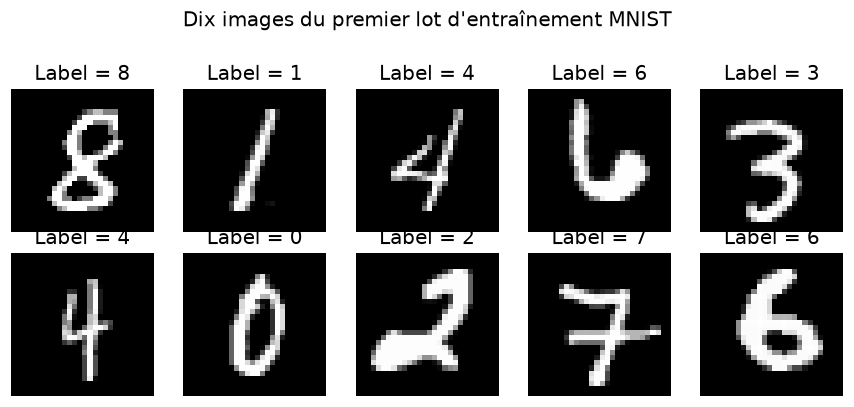

In [3]:
images, labels = next(iter(train_loader))

fig, axes = plt.subplots(2, 5, figsize=(8, 3.6))
for i, ax in enumerate(axes.flat):
    ax.imshow(images[i].squeeze(), cmap="gray", vmin=0, vmax=1)
    ax.set_title(f"Label = {int(labels[i])}")
    ax.axis("off")
fig.suptitle("Dix images du premier lot d'entraînement MNIST", y=1.02)
fig.tight_layout()
save_figure(fig, "mnist_exemples.png")
plt.show()
plt.close(fig)

Les dix vignettes ci-dessus sont des exemples réels de MNIST. Le fond est proche de 0 et le trait manuscrit est proche de 1. L'étiquette affichée est la classe fournie avec l'image : elle servira au classifieur, mais pas à l'entraînement de l'autoencodeur ni du VAE.

Le dernier lot d'entraînement contient 96 images et non 128. Les boucles qui suivent pondèrent donc les pertes par le nombre d'exemples réellement vus, afin que ce lot court ne compte pas autant qu'un lot complet.

## 4. Partie I — Modèle discriminatif

### Objectif

Le classifieur doit reconnaître le chiffre présent dans une image.

```text
Image MNIST  →  Réseau de neurones  →  Prédiction de classe
```

Il apprend une frontière entre les dix classes. Il ne dispose d'aucun décodeur : rien, dans son architecture ni dans sa perte, ne lui demande de produire des pixels. C'est le point de départ qui rendra ensuite visible la différence avec un modèle génératif.

### Architecture du cours

Le réseau est entièrement connecté :

```text
[B, 1, 28, 28] → Flatten → [B, 784] → Linéaire 128 → ReLU → Linéaire 10
```

- `nn.Flatten()` ne change pas les valeurs. Il transforme chaque image en vecteur pour qu'une couche `Linear` puisse la lire. Sans cet aplatissement, la couche attendrait 28 entrées et non 784.
- **784** est le nombre de pixels : \(1 \times 28 \times 28\).
- Les **128 neurones cachés** forment une représentation intermédiaire apprise. Cette largeur est un compromis de capacité, pas une valeur imposée par les données.
- **ReLU** introduit une non-linéarité. Sans elle, l'empilement de deux couches linéaires resterait une seule transformation linéaire.
- Les **10 sorties** sont les scores des chiffres 0 à 9. Ce sont des **logits**, pas des probabilités : ils ne sont pas contraints de sommer à 1. `CrossEntropyLoss` applique elle-même le log-softmax. Il ne faut donc pas ajouter de `Softmax` avant cette perte.

In [4]:
class Classifier(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            nn.Flatten(),
            nn.Linear(784, 128),
            nn.ReLU(),
            nn.Linear(128, 10),
        )

    def forward(self, x):
        return self.net(x)


reseed(SEED)
classifier = Classifier().to(device)

batch_x, batch_y = next(iter(train_loader))
logits = classifier(batch_x.to(device))
print(classifier)
print("Entrée :", tuple(batch_x.shape))
print("Logits :", tuple(logits.shape))
assert logits.shape == (batch_x.shape[0], 10)
assert torch.isfinite(logits).all()

Classifier(
  (net): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=784, out_features=128, bias=True)
    (2): ReLU()
    (3): Linear(in_features=128, out_features=10, bias=True)
  )
)
Entrée : (128, 1, 28, 28)
Logits : (128, 10)


La forme `[batch_size, 10]` confirme qu'il y a un score par classe et par image du lot. Comme le DataLoader mélange les données, ce premier lot n'a pas nécessairement 128 images affichées dans le message précédent si l'itérateur a déjà été consommé : la vérification utilise la taille réelle du lot, y compris lorsqu'elle est inférieure à 128.

### Entraînement

La perte est l'entropie croisée multi-classes. L'optimiseur est Adam, avec un pas de \(10^{-3}\), pendant **3 époques**.

Pour chaque lot :

1. `model.train()` active le mode entraînement.
2. Le lot est chargé puis déplacé sur le même périphérique que le modèle.
3. Le modèle calcule les logits.
4. `CrossEntropyLoss` compare ces logits aux étiquettes.
5. `optimizer.zero_grad()` efface les gradients du lot précédent.
6. `loss.backward()` les calcule.
7. `optimizer.step()` met à jour les poids.

La perte affichée est la moyenne **par image**, pondérée par la taille de chaque lot.

Epoch 1/3 - Loss = 0.4076


Epoch 2/3 - Loss = 0.1905


Epoch 3/3 - Loss = 0.1389
Figure enregistrée : C:\Users\amald\Desktop\TP_ai_générative_N2\results\classifier\courbe_perte.png


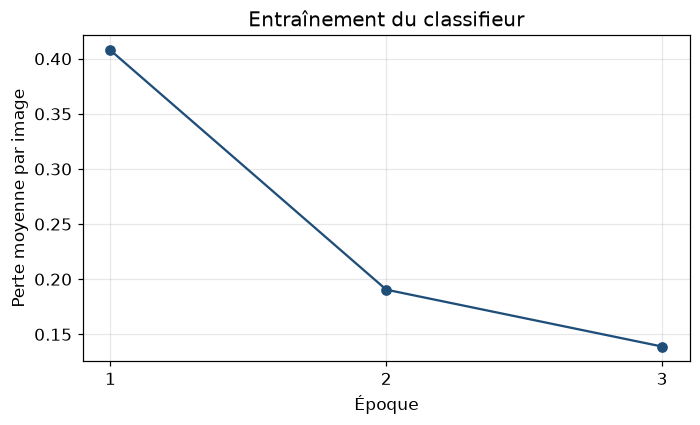

In [5]:
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(classifier.parameters(), lr=1e-3)


def train_classifier(model, loader, epochs=EPOCHS_CLASSIFIER):
    history = []
    batch_sizes = []

    for epoch in range(epochs):
        model.train()
        total_loss = 0.0
        n_seen = 0

        for x, y in loader:
            x = x.to(device)
            y = y.to(device)
            batch_sizes.append(x.size(0))

            logits = model(x)
            loss = criterion(logits, y)

            optimizer.zero_grad()
            loss.backward()
            optimizer.step()

            # CrossEntropyLoss moyenne le lot : on revient à une somme, puis à une moyenne globale.
            total_loss += loss.item() * x.size(0)
            n_seen += x.size(0)

        epoch_loss = total_loss / n_seen
        assert math.isfinite(epoch_loss)
        history.append(epoch_loss)
        print(f"Epoch {epoch + 1}/{epochs} - Loss = {epoch_loss:.4f}")

    assert n_seen == len(loader.dataset)
    assert 128 in batch_sizes
    assert 96 in batch_sizes
    return history


classifier_history = train_classifier(classifier, train_loader, epochs=EPOCHS_CLASSIFIER)

fig, ax = plt.subplots(figsize=(6.5, 4))
ax.plot(
    np.arange(1, len(classifier_history) + 1),
    classifier_history,
    marker="o",
    color="#1f4e79",
)
ax.set_xticks(np.arange(1, len(classifier_history) + 1))
ax.set_xlabel("Époque")
ax.set_ylabel("Perte moyenne par image")
ax.set_title("Entraînement du classifieur")
ax.grid(True, alpha=0.3)
fig.tight_layout()
save_figure(fig, "classifier/courbe_perte.png")
plt.show()
plt.close(fig)

### Évaluation sur les 10 000 images de test

Le modèle passe en mode évaluation et les gradients sont désactivés : on mesure, on n'apprend plus.

L'accuracy est calculée avec `torcheval.metrics.MulticlassAccuracy`, comme dans le support, et contrôlée par un comptage manuel. La matrice de confusion, la précision macro, le rappel macro et le F1 macro précisent les erreurs. La moyenne macro donne le même poids à chaque chiffre, quel que soit son effectif.

Accuracy              : 96.31 %
Images correctes      : 9631 / 10000
Images mal classées   : 369 / 10000
Précision macro       : 0.9629
Rappel macro          : 0.9627
F1 macro              : 0.9628


Figure enregistrée : C:\Users\amald\Desktop\TP_ai_générative_N2\results\classifier\matrice_confusion.png


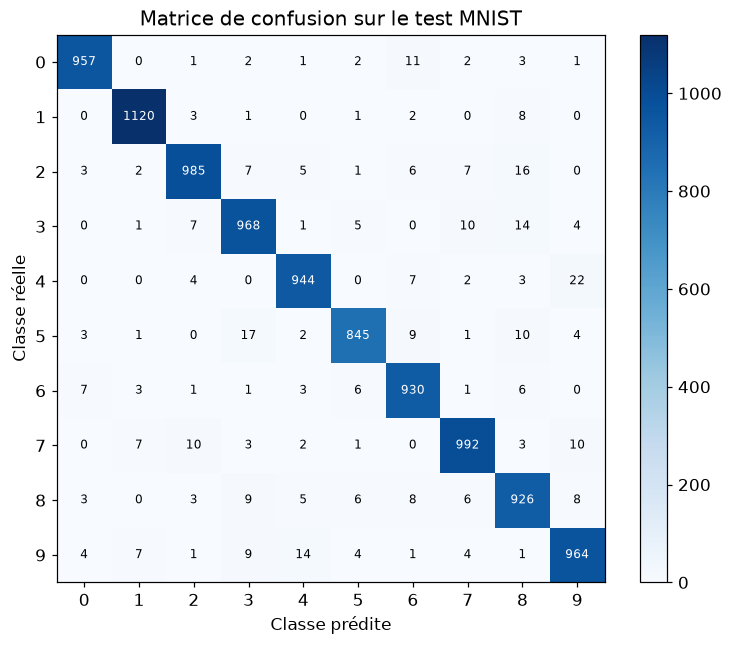

In [6]:
from torcheval.metrics import MulticlassAccuracy


@torch.no_grad()
def evaluate_classifier(model, loader):
    model.eval()
    metric_device = next(model.parameters()).device
    try:
        metric = MulticlassAccuracy(device=metric_device)
    except TypeError:
        metric = MulticlassAccuracy()

    y_true = []
    y_pred = []
    batch_sizes = []

    for x, y in loader:
        x = x.to(device)
        y = y.to(device)
        batch_sizes.append(y.size(0))
        logits = model(x)
        metric.update(logits, y)
        y_true.append(y.cpu())
        y_pred.append(logits.argmax(dim=1).cpu())

    y_true = torch.cat(y_true).numpy()
    y_pred = torch.cat(y_pred).numpy()
    accuracy = float(metric.compute().item())
    correct = int((y_true == y_pred).sum())
    precision, recall, f1, _ = precision_recall_fscore_support(
        y_true,
        y_pred,
        average="macro",
        zero_division=0,
    )
    assert 16 in batch_sizes
    assert len(y_true) == 10_000
    return {
        "accuracy": accuracy,
        "correct": correct,
        "incorrect": int(len(y_true) - correct),
        "precision_macro": float(precision),
        "recall_macro": float(recall),
        "f1_macro": float(f1),
        "y_true": y_true,
        "y_pred": y_pred,
    }


classifier_metrics = evaluate_classifier(classifier, test_loader)
manual_accuracy = classifier_metrics["correct"] / 10_000
assert abs(classifier_metrics["accuracy"] - manual_accuracy) < 1e-6
assert math.isfinite(classifier_metrics["accuracy"])

print(f"Accuracy              : {100 * classifier_metrics['accuracy']:.2f} %")
print(f"Images correctes      : {classifier_metrics['correct']} / 10000")
print(f"Images mal classées   : {classifier_metrics['incorrect']} / 10000")
print(f"Précision macro       : {classifier_metrics['precision_macro']:.4f}")
print(f"Rappel macro          : {classifier_metrics['recall_macro']:.4f}")
print(f"F1 macro              : {classifier_metrics['f1_macro']:.4f}")

cm = confusion_matrix(
    classifier_metrics["y_true"],
    classifier_metrics["y_pred"],
    labels=list(range(10)),
)

fig, ax = plt.subplots(figsize=(7.2, 6))
image = ax.imshow(cm, cmap="Blues")
ax.set_xticks(range(10))
ax.set_yticks(range(10))
ax.set_xlabel("Classe prédite")
ax.set_ylabel("Classe réelle")
ax.set_title("Matrice de confusion sur le test MNIST")
threshold = cm.max() / 2
for i in range(10):
    for j in range(10):
        ax.text(
            j,
            i,
            str(int(cm[i, j])),
            ha="center",
            va="center",
            color="white" if cm[i, j] > threshold else "black",
            fontsize=8,
        )
fig.colorbar(image, ax=ax, fraction=0.046)
fig.tight_layout()
save_figure(fig, "classifier/matrice_confusion.png")
plt.show()
plt.close(fig)

Figure enregistrée : C:\Users\amald\Desktop\TP_ai_générative_N2\results\classifier\predictions.png


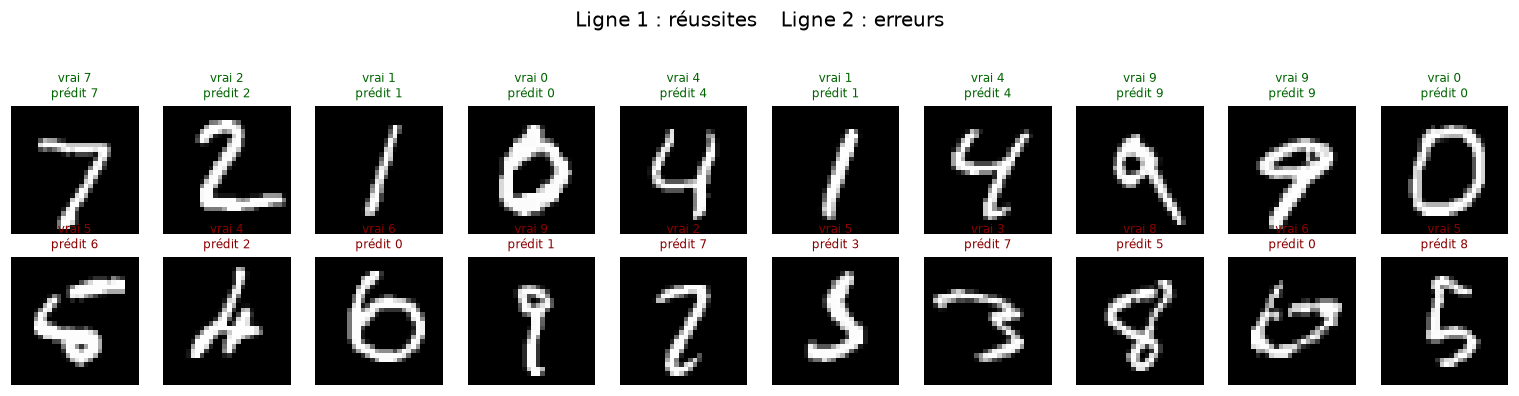

In [7]:
@torch.no_grad()
def collect_prediction_examples(model, dataset, n_each=10):
    model.eval()
    corrects = []
    errors = []
    for image, label in dataset:
        if len(corrects) >= n_each and len(errors) >= n_each:
            break
        logits = model(image.unsqueeze(0).to(device))
        prediction = int(logits.argmax(dim=1).item())
        label = int(label)
        item = (image.squeeze().cpu(), label, prediction)
        if prediction == label and len(corrects) < n_each:
            corrects.append(item)
        elif prediction != label and len(errors) < n_each:
            errors.append(item)
    return corrects, errors


correct_examples, error_examples = collect_prediction_examples(
    classifier, test_dataset, n_each=10
)
assert len(correct_examples) == 10
assert len(error_examples) == 10

fig, axes = plt.subplots(2, 10, figsize=(14, 3.4))
for ax, (image, label, prediction) in zip(axes[0], correct_examples):
    ax.imshow(image, cmap="gray", vmin=0, vmax=1)
    ax.set_title(f"vrai {label}\nprédit {prediction}", color="darkgreen", fontsize=8)
    ax.axis("off")
for ax, (image, label, prediction) in zip(axes[1], error_examples):
    ax.imshow(image, cmap="gray", vmin=0, vmax=1)
    ax.set_title(f"vrai {label}\nprédit {prediction}", color="darkred", fontsize=8)
    ax.axis("off")
fig.suptitle("Ligne 1 : réussites    Ligne 2 : erreurs", y=1.05)
fig.tight_layout()
save_figure(fig, "classifier/predictions.png")
plt.show()
plt.close(fig)

### Sauvegarde et rechargement

Les poids sont enregistrés dans `models/classifier_mnist.pth`. Une nouvelle instance, qui ne partage pas la mémoire du modèle entraîné, recharge ces poids. Sur un même lot de test, les logits et les classes prédites doivent coïncider.

In [8]:
classifier_path = MODELS_DIR / "classifier_mnist.pth"
torch.save(classifier.state_dict(), classifier_path)

reloaded_classifier = Classifier().to(device)
reloaded_classifier.load_state_dict(
    torch.load(classifier_path, map_location=device, weights_only=True)
)
reloaded_classifier.eval()
classifier.eval()

check_x, check_y = next(iter(test_loader))
check_x = check_x.to(device)
with torch.no_grad():
    logits_a = classifier(check_x)
    logits_b = reloaded_classifier(check_x)

assert check_x.shape[0] <= BATCH_SIZE
assert torch.allclose(logits_a, logits_b, atol=1e-5)
assert torch.equal(logits_a.argmax(dim=1), logits_b.argmax(dim=1))
print("Sauvegarde vérifiée :", classifier_path)
print("Prédictions identiques sur un lot de", check_x.shape[0], "images.")

Sauvegarde vérifiée : C:\Users\amald\Desktop\TP_ai_générative_N2\models\classifier_mnist.pth
Prédictions identiques sur un lot de 128 images.


In [9]:
cm_off = cm.copy()
np.fill_diagonal(cm_off, 0)
true_digit, predicted_digit = np.unravel_index(cm_off.argmax(), cm_off.shape)

print(
    f"Sur les 10 000 images de test, le classifieur atteint "
    f"{100 * classifier_metrics['accuracy']:.2f} % d'accuracy "
    f"après {EPOCHS_CLASSIFIER} époques."
)
print(
    f"Il classe correctement {classifier_metrics['correct']} images "
    f"et se trompe sur {classifier_metrics['incorrect']} images. "
    f"Un choix uniforme au hasard réussirait environ 10 % des cas."
)
print(
    f"La confusion la plus fréquente va du chiffre {int(true_digit)} "
    f"vers le chiffre {int(predicted_digit)} "
    f"({int(cm_off[true_digit, predicted_digit])} images)."
)
print(
    "Le F1 macro de "
    f"{classifier_metrics['f1_macro']:.4f} est cohérent avec l'accuracy : "
    "aucune classe n'est entièrement ignorée. "
    "Le modèle discrimine les chiffres. Il ne sait pas en dessiner un nouveau, "
    "parce que sa sortie est un vecteur de 10 logits et non une image."
)

Sur les 10 000 images de test, le classifieur atteint 96.31 % d'accuracy après 3 époques.
Il classe correctement 9631 images et se trompe sur 369 images. Un choix uniforme au hasard réussirait environ 10 % des cas.
La confusion la plus fréquente va du chiffre 4 vers le chiffre 9 (22 images).
Le F1 macro de 0.9628 est cohérent avec l'accuracy : aucune classe n'est entièrement ignorée. Le modèle discrimine les chiffres. Il ne sait pas en dessiner un nouveau, parce que sa sortie est un vecteur de 10 logits et non une image.


## 5. Partie II — Autoencodeur classique

### Idée

Un autoencodeur n'utilise pas l'étiquette. Il apprend à reconstruire son entrée après l'avoir comprimée.

```text
Image originale → Encodeur → Code latent z → Décodeur → Image reconstruite
```

Trois éléments suffisent à le décrire.

- **L'encodeur** transforme les 784 pixels en un vecteur court.
- **L'espace latent** est l'espace de ces vecteurs. Ici, il a deux coordonnées, ce qui permet de dessiner chaque image comme un point.
- **Le décodeur** fait le chemin inverse, du code vers une image de 28 × 28.

Reconstruire n'est pas générer. La reconstruction part d'une image réelle, déjà vue par l'encodeur. Une génération autonome partirait d'un code choisi sans image. Rien, pour l'instant, n'apprend au décodeur quelle région de l'espace latent est autorisée.

### Architecture du cours

`latent_dim = 2`.

```text
Encodeur : 784 → 128 → 32 → 2
Décodeur : 2 → 32 → 128 → 784
```

ReLU active les couches intermédiaires. La sigmoïde finale ramène chaque pixel dans \([0, 1]\), dans la même échelle que `ToTensor()`.

Deux dimensions sont commodes pour un nuage de points. Elles forment aussi un goulet d'étranglement sévère : beaucoup de détails de l'écriture ne peuvent pas tenir dans deux nombres. C'est un choix de visualisation, pas la représentation la plus fidèle possible.

In [10]:
class Autoencoder(nn.Module):
    def __init__(self, latent_dim=2):
        super().__init__()

        self.encoder = nn.Sequential(
            nn.Flatten(),
            nn.Linear(784, 128),
            nn.ReLU(),
            nn.Linear(128, 32),
            nn.ReLU(),
            nn.Linear(32, latent_dim),
        )

        self.decoder = nn.Sequential(
            nn.Linear(latent_dim, 32),
            nn.ReLU(),
            nn.Linear(32, 128),
            nn.ReLU(),
            nn.Linear(128, 784),
            nn.Sigmoid(),
        )

    def encode(self, x):
        return self.encoder(x)

    def decode(self, z):
        x_hat = self.decoder(z)
        return x_hat.view(-1, 1, 28, 28)

    def forward(self, x):
        z = self.encode(x)
        return self.decode(z)


reseed(SEED)
ae = Autoencoder(latent_dim=LATENT_DIM).to(device)

shape_x, _ = next(iter(test_loader))
shape_x = shape_x.to(device)
with torch.no_grad():
    z_shape = ae.encode(shape_x)
    x_hat_shape = ae(shape_x)

print(ae)
print("Code latent :", tuple(z_shape.shape))
print("Reconstruction :", tuple(x_hat_shape.shape))
assert z_shape.shape == (shape_x.shape[0], LATENT_DIM)
assert x_hat_shape.shape == (shape_x.shape[0], 1, 28, 28)
assert float(x_hat_shape.min()) >= 0.0
assert float(x_hat_shape.max()) <= 1.0

Autoencoder(
  (encoder): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=784, out_features=128, bias=True)
    (2): ReLU()
    (3): Linear(in_features=128, out_features=32, bias=True)
    (4): ReLU()
    (5): Linear(in_features=32, out_features=2, bias=True)
  )
  (decoder): Sequential(
    (0): Linear(in_features=2, out_features=32, bias=True)
    (1): ReLU()
    (2): Linear(in_features=32, out_features=128, bias=True)
    (3): ReLU()
    (4): Linear(in_features=128, out_features=784, bias=True)
    (5): Sigmoid()
  )
)
Code latent : (128, 2)
Reconstruction : (128, 1, 28, 28)


### Entraînement

La perte est l'erreur quadratique moyenne entre l'image et sa reconstruction. Adam garde le pas \(10^{-3}\). L'entraînement dure **5 époques**. Les étiquettes sont ignorées : la cible est l'image elle-même.

Une MSE faible signifie que les pixels reconstruits sont, en moyenne, proches des pixels d'origine. Elle ne garantit pas une bonne qualité perçue. Deux images peuvent avoir la même erreur quadratique alors que l'une reste lisible et l'autre est floue, parce que la MSE traite chaque pixel indépendamment et pénalise surtout les écarts numériques.

Epoch 1/5 - Loss = 0.0657


Epoch 2/5 - Loss = 0.0514


Epoch 3/5 - Loss = 0.0475


Epoch 4/5 - Loss = 0.0450


Epoch 5/5 - Loss = 0.0436


MSE moyenne sur les 10 000 images de test : 0.0432
RMSE par pixel : 0.2078 sur une échelle de 0 à 1.


Figure enregistrée : C:\Users\amald\Desktop\TP_ai_générative_N2\results\autoencoder\courbe_perte.png


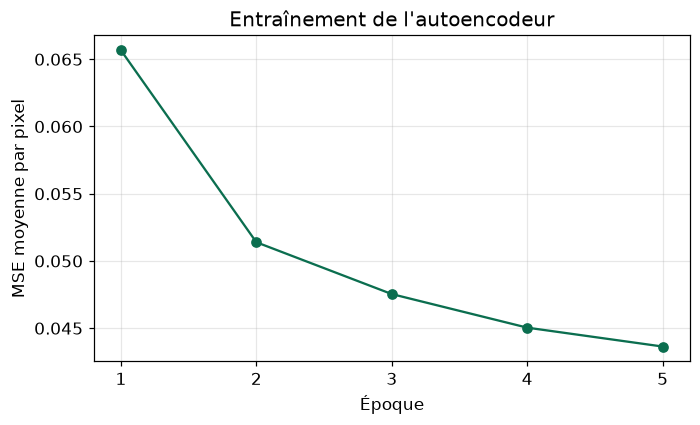

In [11]:
ae_criterion = nn.MSELoss()
ae_optimizer = torch.optim.Adam(ae.parameters(), lr=1e-3)


def train_autoencoder(model, loader, epochs=EPOCHS_AUTOENCODER):
    history = []
    for epoch in range(epochs):
        model.train()
        total_loss = 0.0
        n_values = 0

        for x, _ in loader:
            x = x.to(device)
            x_hat = model(x)
            loss = ae_criterion(x_hat, x)

            ae_optimizer.zero_grad()
            loss.backward()
            ae_optimizer.step()

            total_loss += loss.item() * x.numel()
            n_values += x.numel()

        epoch_loss = total_loss / n_values
        assert math.isfinite(epoch_loss)
        history.append(epoch_loss)
        print(f"Epoch {epoch + 1}/{epochs} - Loss = {epoch_loss:.4f}")
    return history


@torch.no_grad()
def reconstruction_mse(model, loader):
    model.eval()
    total_loss = 0.0
    n_values = 0
    pixel_min = 1.0
    pixel_max = 0.0
    for x, _ in loader:
        x = x.to(device)
        x_hat = model(x)
        total_loss += F.mse_loss(x_hat, x, reduction="sum").item()
        n_values += x.numel()
        pixel_min = min(pixel_min, float(x_hat.min()))
        pixel_max = max(pixel_max, float(x_hat.max()))
    mse = total_loss / n_values
    assert math.isfinite(mse)
    assert 0.0 <= pixel_min and pixel_max <= 1.0
    return mse


ae_history = train_autoencoder(ae, train_loader, epochs=EPOCHS_AUTOENCODER)
ae_test_mse = reconstruction_mse(ae, test_loader)
print(f"MSE moyenne sur les 10 000 images de test : {ae_test_mse:.4f}")
print(f"RMSE par pixel : {math.sqrt(ae_test_mse):.4f} sur une échelle de 0 à 1.")

fig, ax = plt.subplots(figsize=(6.5, 4))
ax.plot(np.arange(1, len(ae_history) + 1), ae_history, marker="o", color="#0b6e4f")
ax.set_xticks(np.arange(1, len(ae_history) + 1))
ax.set_xlabel("Époque")
ax.set_ylabel("MSE moyenne par pixel")
ax.set_title("Entraînement de l'autoencodeur")
ax.grid(True, alpha=0.3)
fig.tight_layout()
save_figure(fig, "autoencoder/courbe_perte.png")
plt.show()
plt.close(fig)

### Reconstructions

Les dix premières images du jeu de test, dans l'ordre fixe de MNIST, servent de référence visuelle. Le même choix sera réutilisé pour le VAE, afin que la comparaison porte sur les mêmes chiffres.

Figure enregistrée : C:\Users\amald\Desktop\TP_ai_générative_N2\results\autoencoder\reconstructions.png


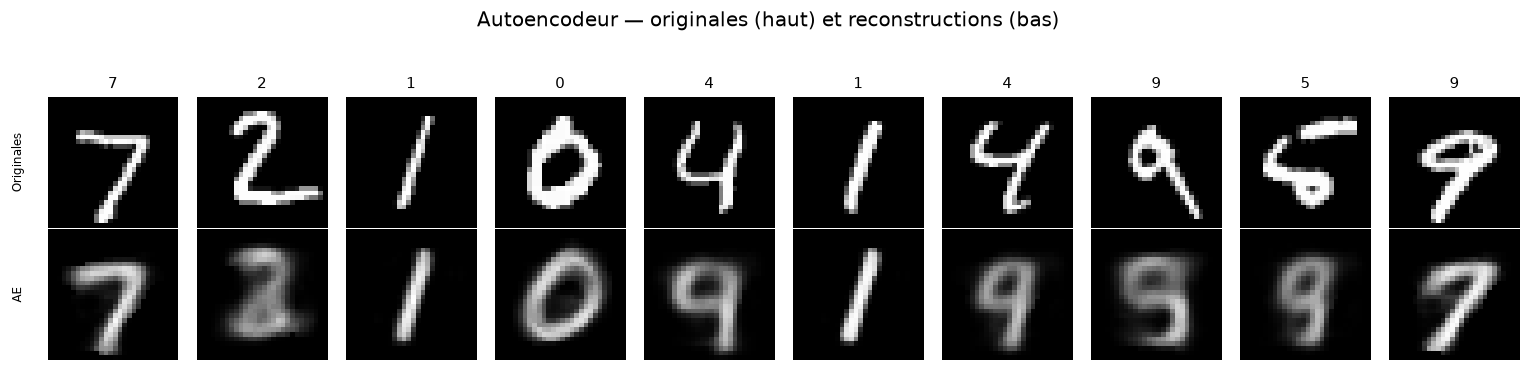

Chiffres affichés : [7, 2, 1, 0, 4, 1, 4, 9, 5, 9]


In [12]:
fixed_images = torch.stack([test_dataset[i][0] for i in range(10)])
fixed_labels = [int(test_dataset[i][1]) for i in range(10)]

ae.eval()
with torch.no_grad():
    fixed_ae = ae(fixed_images.to(device)).cpu()

assert fixed_ae.shape == (10, 1, 28, 28)
assert float(fixed_ae.min()) >= 0.0 and float(fixed_ae.max()) <= 1.0

fig, axes = plt.subplots(2, 10, figsize=(14, 3.2))
for i in range(10):
    axes[0, i].imshow(fixed_images[i].squeeze(), cmap="gray", vmin=0, vmax=1)
    axes[0, i].set_title(str(fixed_labels[i]), fontsize=10)
    axes[0, i].axis("off")
    axes[1, i].imshow(fixed_ae[i].squeeze(), cmap="gray", vmin=0, vmax=1)
    axes[1, i].axis("off")
label_row(axes[0, 0], "Originales")
label_row(axes[1, 0], "AE")
fig.suptitle("Autoencodeur — originales (haut) et reconstructions (bas)", y=1.05)
fig.tight_layout()
save_figure(fig, "autoencoder/reconstructions.png")
plt.show()
plt.close(fig)
print("Chiffres affichés :", fixed_labels)

La ligne du bas conserve en général la famille du chiffre : un 1 reste mince, un 0 reste une boucle. Le trait précis, l'inclinaison et les petites variations d'écriture disparaissent souvent. C'est l'effet attendu d'un code à deux dimensions. L'image reconstruite ressemble à un prototype lisse plutôt qu'à la copie exacte du manuscrit.

### Espace latent

Chaque image de test est encodée en un point \((z_1, z_2)\). La couleur n'a pas servi à l'entraînement : elle indique seulement le chiffre réel, pour nous permettre de lire l'organisation apprise.

Figure enregistrée : C:\Users\amald\Desktop\TP_ai_générative_N2\results\autoencoder\espace_latent.png


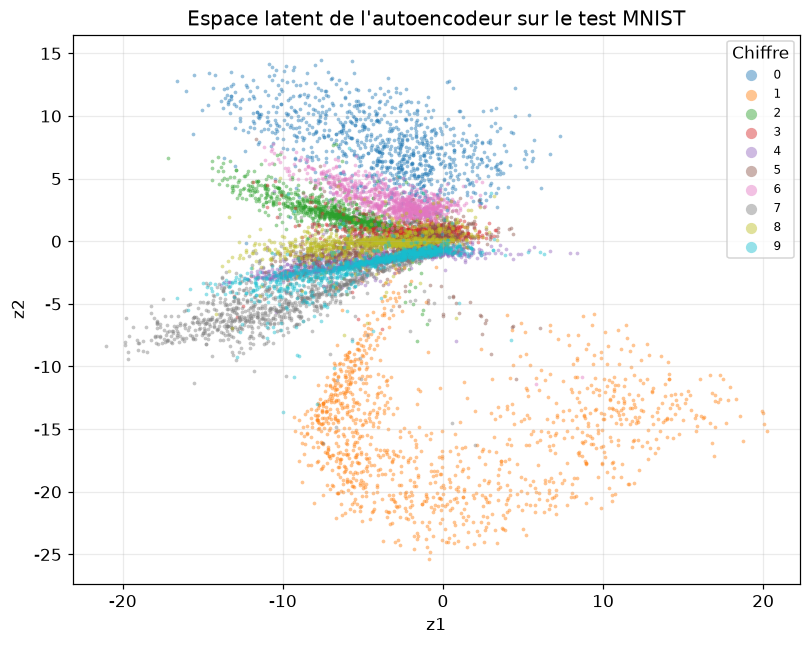

z1 dans [-21.07, 20.22]
z2 dans [-25.34, 14.51]
Score de silhouette : -0.0078


In [13]:
@torch.no_grad()
def collect_ae_latents(model, loader):
    model.eval()
    latents = []
    labels = []
    for x, y in loader:
        latents.append(model.encode(x.to(device)).cpu())
        labels.append(y)
    return torch.cat(latents).numpy(), torch.cat(labels).numpy()


Z_ae, Y_ae = collect_ae_latents(ae, test_loader)
assert Z_ae.shape == (10_000, 2)
assert Y_ae.shape == (10_000,)
silhouette_ae = float(silhouette_score(Z_ae, Y_ae))

fig, ax = plt.subplots(figsize=(7.5, 6))
cmap = plt.get_cmap("tab10")
for digit in range(10):
    mask = Y_ae == digit
    ax.scatter(
        Z_ae[mask, 0],
        Z_ae[mask, 1],
        s=6,
        alpha=0.45,
        color=cmap(digit),
        label=str(digit),
        linewidths=0,
    )
ax.set_xlabel("z1")
ax.set_ylabel("z2")
ax.set_title("Espace latent de l'autoencodeur sur le test MNIST")
ax.legend(title="Chiffre", markerscale=3, fontsize=8, frameon=True)
ax.grid(True, alpha=0.25)
fig.tight_layout()
save_figure(fig, "autoencoder/espace_latent.png")
plt.show()
plt.close(fig)

print(f"z1 dans [{Z_ae[:, 0].min():.2f}, {Z_ae[:, 0].max():.2f}]")
print(f"z2 dans [{Z_ae[:, 1].min():.2f}, {Z_ae[:, 1].max():.2f}]")
print(f"Score de silhouette : {silhouette_ae:.4f}")

### Comment lire ce nuage

- Un **regroupement** de même couleur signifie que l'encodeur a placé des écritures du même chiffre dans une zone voisine.
- Un **chevauchement** signifie que deux chiffres partagent des codes proches. Le décodeur aura alors du mal à les distinguer, parce qu'il ne reçoit que ces deux coordonnées.
- La **distance** entre deux points est une distance dans le code, pas une distance en pixels. Deux images proches dans l'image peuvent être éloignées dans le latent, et inversement.
- Cet espace n'est pas une carte géographique fiable. Les axes \(z_1\) et \(z_2\) n'ont pas de signification fixée à l'avance : une autre initialisation peut tourner ou étirer la figure. On interprète les voisinages, pas les coordonnées absolues.

### Décodage du code latent moyen d'un chiffre

La fonction du cours `generer_chiffre` ne tire pas un code au hasard. Elle sélectionne les images d'un chiffre connu, encode chacune d'elles, moyenne ces codes, puis décode cette moyenne. Le résultat est le décodage d'un prototype déjà observé.

Figure enregistrée : C:\Users\amald\Desktop\TP_ai_générative_N2\results\autoencoder\chiffres_moyens.png


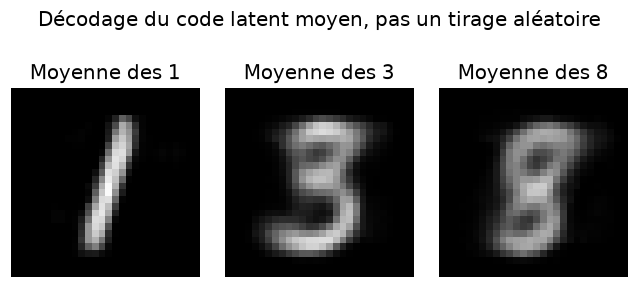

In [14]:
@torch.no_grad()
def generer_chiffre(model, dataloader, chiffre):
    if chiffre not in range(10):
        raise ValueError("Le chiffre doit être compris entre 0 et 9.")

    device_model = next(model.parameters()).device
    model.eval()

    somme_z = None
    nombre = 0

    for images, labels in dataloader:
        images = images[labels == chiffre]
        if images.shape[0] == 0:
            continue

        z = model.encode(images.to(device_model))
        if somme_z is None:
            somme_z = z.sum(dim=0, keepdim=True)
        else:
            somme_z += z.sum(dim=0, keepdim=True)
        nombre += z.shape[0]

    if nombre == 0:
        raise ValueError(f"Aucune image du chiffre {chiffre} trouvée.")

    z_moyen = somme_z / nombre
    return model.decode(z_moyen).cpu()


digits_to_show = (1, 3, 8)
mean_digits = [generer_chiffre(ae, train_loader, digit) for digit in digits_to_show]
for image in mean_digits:
    assert image.shape == (1, 1, 28, 28)
    assert float(image.min()) >= 0.0 and float(image.max()) <= 1.0

fig, axes = plt.subplots(1, 3, figsize=(6, 2.4))
for ax, digit, image in zip(axes, digits_to_show, mean_digits):
    ax.imshow(image[0, 0], cmap="gray", vmin=0, vmax=1)
    ax.set_title(f"Moyenne des {digit}")
    ax.axis("off")
fig.suptitle("Décodage du code latent moyen, pas un tirage aléatoire", y=1.08)
fig.tight_layout()
save_figure(fig, "autoencoder/chiffres_moyens.png")
plt.show()
plt.close(fig)

Les images des chiffres 1, 3 et 8 ci-dessus sont obtenues en **décodant le code latent moyen de chiffres connus**. Ce n'est pas une génération fiable de nouveaux manuscrits par échantillonnage aléatoire. Si l'on retire les exemples de ce chiffre, la fonction ne sait plus où placer ce prototype.

### Limites de l'autoencodeur

L'autoencodeur classique est d'abord un modèle de **reconstruction**. Son espace latent n'est pas régularisé : aucune perte ne le rapproche d'une loi connue. Les codes des images réelles occupent une région que l'entraînement a visitée. Un vecteur tiré ailleurs, par exemple dans une gaussienne standard, n'a aucune raison d'être un code que le décodeur sait interpréter.

L'expérience suivante le montre directement. La première ligne décode dix vecteurs \(\mathcal{N}(0, I)\). La seconde décode dix vecteurs tirés uniformément dans le rectangle observé sur le jeu de test. Même à l'intérieur de ce rectangle, un point peut tomber entre deux groupes et produire une forme ambiguë.

Figure enregistrée : C:\Users\amald\Desktop\TP_ai_générative_N2\results\autoencoder\echantillons_aleatoires.png


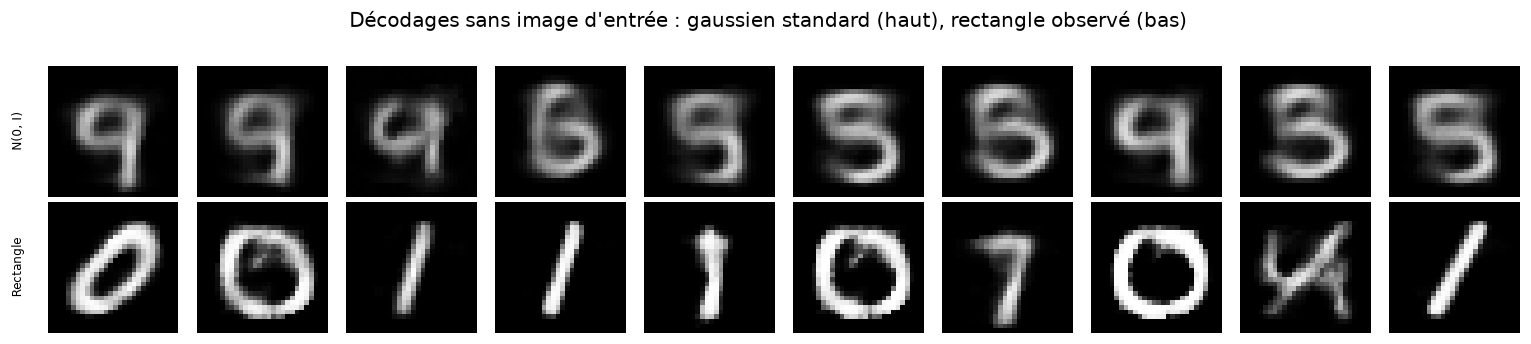

Ces images ne constituent pas une procédure de génération. Elles motivent le VAE, qui rapproche explicitement l'espace latent de N(0, I).


In [15]:
generator_ae = torch.Generator()
generator_ae.manual_seed(0)

ae.eval()
with torch.no_grad():
    z_gaussian = torch.randn(10, LATENT_DIM, generator=generator_ae).to(device)
    images_gaussian = ae.decode(z_gaussian).cpu()

    z_low = torch.tensor(Z_ae.min(axis=0), dtype=torch.float32, device=device)
    z_high = torch.tensor(Z_ae.max(axis=0), dtype=torch.float32, device=device)
    z_uniform = z_low + torch.rand(10, LATENT_DIM, generator=generator_ae).to(device) * (
        z_high - z_low
    )
    images_uniform = ae.decode(z_uniform).cpu()

fig, axes = plt.subplots(2, 10, figsize=(14, 3.2))
for i in range(10):
    axes[0, i].imshow(images_gaussian[i, 0], cmap="gray", vmin=0, vmax=1)
    axes[0, i].axis("off")
    axes[1, i].imshow(images_uniform[i, 0], cmap="gray", vmin=0, vmax=1)
    axes[1, i].axis("off")
label_row(axes[0, 0], "N(0, I)")
label_row(axes[1, 0], "Rectangle")
fig.suptitle("Décodages sans image d'entrée : gaussien standard (haut), rectangle observé (bas)")
fig.tight_layout()
save_figure(fig, "autoencoder/echantillons_aleatoires.png")
plt.show()
plt.close(fig)
print(
    "Ces images ne constituent pas une procédure de génération. "
    "Elles motivent le VAE, qui rapproche explicitement l'espace latent de N(0, I)."
)

In [16]:
ae_path = MODELS_DIR / "autoencoder_mnist.pth"
torch.save(ae.state_dict(), ae_path)

reloaded_ae = Autoencoder(latent_dim=LATENT_DIM).to(device)
reloaded_ae.load_state_dict(torch.load(ae_path, map_location=device, weights_only=True))
reloaded_ae.eval()
ae.eval()
with torch.no_grad():
    original_batch = ae(check_x)
    reloaded_batch = reloaded_ae(check_x)
assert torch.allclose(original_batch, reloaded_batch, atol=1e-5)
print("Sauvegarde vérifiée :", ae_path)

Sauvegarde vérifiée : C:\Users\amald\Desktop\TP_ai_générative_N2\models\autoencoder_mnist.pth


## 6. Partie III — Variational Autoencoder (VAE)

### Du code déterministe à une distribution

L'autoencodeur associe chaque image à un point :

```text
Image → code latent déterministe z → reconstruction
```

Le VAE associe chaque image à une **loi de probabilité**, puis tire un code dans cette loi :

```text
Image → paramètres (mu, logvar) → échantillon z → reconstruction
```

L'encodeur ne prédit plus directement \(z\). Il prédit les paramètres d'une gaussienne diagonale

$$
q(z \mid x) = \mathcal{N}\big(\mu(x),\ \mathrm{diag}(\sigma^2(x))\big).
$$

- \(\mu\) est la moyenne de cette gaussienne, un vecteur de dimension 2.
- La **variance** \(\sigma^2\) doit rester positive. Le réseau prédit plutôt son logarithme, `logvar` \(= \log \sigma^2\). L'exponentielle garantit ensuite \(\sigma^2 > 0\).
- L'**écart-type** est \(\sigma = \sqrt{\sigma^2} = \exp(0{,}5 \cdot \log \sigma^2)\).
- L'espace latent est **probabiliste** : une même image correspond à un nuage de codes possibles, concentré autour de \(\mu\).
- La loi a priori, imposée par la régularisation, est

$$
p(z) = \mathcal{N}(0, I).
$$

### Reparamétrisation

Tirer \(z\) directement dans \(\mathcal{N}(\mu, \sigma^2)\) casserait le graphe de calcul : l'opération de tirage n'est pas dérivable par rapport à \(\mu\) et \(\sigma\). On réécrit le tirage

$$
\epsilon \sim \mathcal{N}(0, I), \qquad z = \mu + \sigma \odot \epsilon.
$$

Le hasard est isolé dans \(\epsilon\), qui ne dépend pas des paramètres. Les gradients traversent \(\mu\) et \(\sigma\). C'est le **reparameterization trick**. Deux passages sur la même image produisent deux \(\epsilon\) différents, donc deux codes \(z\) différents.

### Perte

La perte du cours additionne une reconstruction et une divergence de Kullback-Leibler :

$$
\mathcal{L}_{\mathrm{VAE}} = \mathcal{L}_{\mathrm{rec}} + \beta\, D_{\mathrm{KL}}\big(q(z \mid x)\,\Vert\, p(z)\big).
$$

La reconstruction est une entropie croisée binaire, naturelle quand les pixels sont vus comme des probabilités dans \([0, 1]\) et que la sortie est une sigmoïde. Avec \(p(z) = \mathcal{N}(0, I)\) et une gaussienne diagonale,

$$
D_{\mathrm{KL}} = -\frac{1}{2} \sum_j \big(1 + \log \sigma_j^2 - \mu_j^2 - \sigma_j^2\big).
$$

Le coefficient \(\beta\) règle le compromis. \(\beta = 1\) correspond au poids standard de l'ELBO. Un \(\beta\) plus grand organise davantage l'espace latent, au risque d'un **posterior collapse** : \(q(z \mid x)\) ignore \(x\), se confond avec le prior, et le décodeur n'utilise plus le code. Un \(\beta\) nul supprime la régularisation et rapproche le VAE d'un autoencodeur probabiliste non contraint.

Dans le code du cours, la BCE et la KL sont toutes deux réduites par une **somme**. Les valeurs affichées sont ensuite divisées par le nombre d'images, pour obtenir une moyenne par image. Cette moyenne reste une somme sur les 784 pixels : elle n'est pas une moyenne par pixel, et elle n'est pas comparable à la MSE de l'autoencodeur.

In [17]:
class VAE(nn.Module):
    def __init__(self, latent_dim=2):
        super().__init__()

        self.encoder = nn.Sequential(
            nn.Flatten(),
            nn.Linear(784, 256),
            nn.ReLU(),
            nn.Linear(256, 64),
            nn.ReLU(),
        )
        self.fc_mu = nn.Linear(64, latent_dim)
        self.fc_logvar = nn.Linear(64, latent_dim)

        self.decoder = nn.Sequential(
            nn.Linear(latent_dim, 64),
            nn.ReLU(),
            nn.Linear(64, 256),
            nn.ReLU(),
            nn.Linear(256, 784),
            nn.Sigmoid(),
        )

    def encode(self, x):
        h = self.encoder(x)
        return self.fc_mu(h), self.fc_logvar(h)

    def reparameterize(self, mu, logvar):
        std = torch.exp(0.5 * logvar)
        eps = torch.randn_like(std)
        return mu + std * eps

    def decode(self, z):
        x_hat = self.decoder(z)
        return x_hat.view(-1, 1, 28, 28)

    def forward(self, x):
        mu, logvar = self.encode(x)
        z = self.reparameterize(mu, logvar)
        x_hat = self.decode(z)
        return x_hat, mu, logvar


def vae_loss(x_hat, x, mu, logvar, beta=1.0):
    rec_loss = F.binary_cross_entropy(
        x_hat,
        x,
        reduction="sum",
    )
    kl_loss = -0.5 * torch.sum(1 + logvar - mu.pow(2) - logvar.exp())
    return rec_loss + beta * kl_loss, rec_loss, kl_loss


reseed(SEED)
vae = VAE(latent_dim=LATENT_DIM).to(device)
vae_optimizer = torch.optim.Adam(vae.parameters(), lr=1e-3)

probe_x, _ = next(iter(test_loader))
probe_x = probe_x.to(device)
with torch.no_grad():
    x_hat_probe, mu_probe, logvar_probe = vae(probe_x)
    z_probe = torch.randn(probe_x.shape[0], LATENT_DIM, device=device)
    decoded_probe = vae.decode(z_probe)
    loss_probe, rec_probe, kl_probe = vae_loss(
        x_hat_probe, probe_x, mu_probe, logvar_probe, beta=BETA
    )

print(vae)
print("Reconstruction :", tuple(x_hat_probe.shape))
print("mu            :", tuple(mu_probe.shape))
print("logvar        :", tuple(logvar_probe.shape))
print("decode([B, 2]):", tuple(decoded_probe.shape))
assert x_hat_probe.shape == (probe_x.shape[0], 1, 28, 28)
assert mu_probe.shape == (probe_x.shape[0], LATENT_DIM)
assert logvar_probe.shape == (probe_x.shape[0], LATENT_DIM)
assert decoded_probe.shape == (probe_x.shape[0], 1, 28, 28)
assert torch.isfinite(loss_probe)
assert float(x_hat_probe.min()) >= 0.0 and float(x_hat_probe.max()) <= 1.0
print(
    f"Perte de contrôle sur un lot : totale={loss_probe.item():.1f}, "
    f"BCE={rec_probe.item():.1f}, KL={kl_probe.item():.1f}"
)

VAE(
  (encoder): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=784, out_features=256, bias=True)
    (2): ReLU()
    (3): Linear(in_features=256, out_features=64, bias=True)
    (4): ReLU()
  )
  (fc_mu): Linear(in_features=64, out_features=2, bias=True)
  (fc_logvar): Linear(in_features=64, out_features=2, bias=True)
  (decoder): Sequential(
    (0): Linear(in_features=2, out_features=64, bias=True)
    (1): ReLU()
    (2): Linear(in_features=64, out_features=256, bias=True)
    (3): ReLU()
    (4): Linear(in_features=256, out_features=784, bias=True)
    (5): Sigmoid()
  )
)
Reconstruction : (128, 1, 28, 28)
mu            : (128, 2)
logvar        : (128, 2)
decode([B, 2]): (128, 1, 28, 28)
Perte de contrôle sur un lot : totale=69528.8, BCE=69528.0, KL=0.8


### Pourquoi ces formules

`logvar` évite au réseau de prédire une variance négative. `exp(0.5 * logvar)` convertit ce logarithme en écart-type, parce que

$$
\exp(0{,}5 \log \sigma^2) = \sigma.
$$

`eps` est un bruit gaussien standard, de même forme que `std`. Le produit `std * eps` déplace le bruit à la bonne échelle, puis l'addition de `mu` le centre. Comme `eps` est tiré hors des paramètres appris, `loss.backward()` atteint les couches `fc_mu` et `fc_logvar`.

La cellule suivante illustre ce mécanisme **après** l'entraînement, quand les reconstructions ont un sens. Elle réutilise la première des dix images de test déjà sélectionnées.

### Entraînement

Adam, pas \(10^{-3}\), **20 époques**, \(\beta = 1\). À chaque époque, la perte totale, la BCE et la KL sont des moyennes par image. Pendant l'entraînement, `forward` tire un \(z\) aléatoire. L'évaluation finale sur le test utilisera \(z = \mu\), afin que le chiffre rapporté ne dépende pas d'un tirage.

Epoch 1/20 | Loss=193.02 | Rec=188.77 | KL=4.25


Epoch 2/20 | Loss=165.96 | Rec=161.05 | KL=4.91


Epoch 3/20 | Loss=160.25 | Rec=154.99 | KL=5.26


Epoch 4/20 | Loss=156.34 | Rec=150.78 | KL=5.56


Epoch 5/20 | Loss=153.71 | Rec=147.98 | KL=5.73


Epoch 6/20 | Loss=151.73 | Rec=145.88 | KL=5.85


... (11 outputs left out)

Epoch 18/20 | Loss=142.56 | Rec=136.15 | KL=6.40


Epoch 19/20 | Loss=142.32 | Rec=135.90 | KL=6.43


Epoch 20/20 | Loss=141.93 | Rec=135.48 | KL=6.45


Figure enregistrée : C:\Users\amald\Desktop\TP_ai_générative_N2\results\vae\loss_vae.png


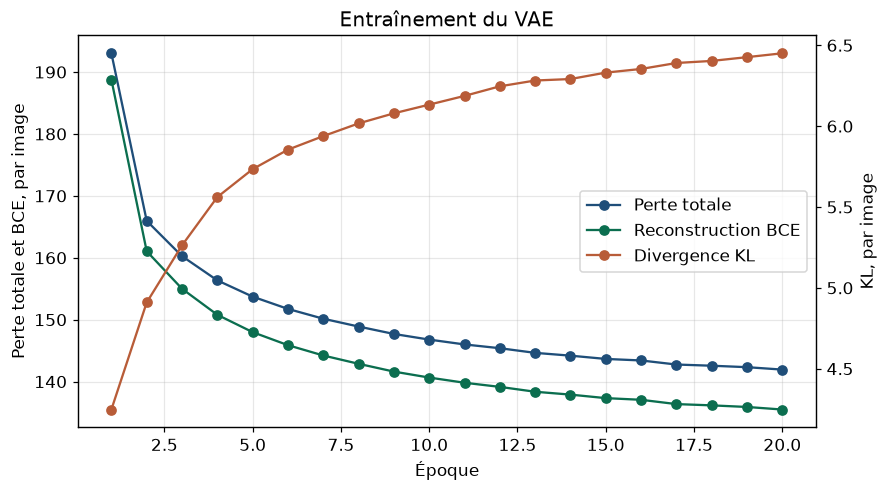

In [18]:
def train_vae(model, loader, epochs=EPOCHS_VAE, beta=BETA):
    history_loss, history_rec, history_kl = [], [], []

    for epoch in range(epochs):
        model.train()
        total_loss = 0.0
        total_rec = 0.0
        total_kl = 0.0
        n_images = 0

        for x, _ in loader:
            x = x.to(device)
            x_hat, mu, logvar = model(x)
            loss, rec, kl = vae_loss(x_hat, x, mu, logvar, beta=beta)

            vae_optimizer.zero_grad()
            loss.backward()
            vae_optimizer.step()

            total_loss += loss.item()
            total_rec += rec.item()
            total_kl += kl.item()
            n_images += x.size(0)

        assert n_images == len(loader.dataset)
        epoch_loss = total_loss / n_images
        epoch_rec = total_rec / n_images
        epoch_kl = total_kl / n_images
        assert math.isfinite(epoch_loss) and math.isfinite(epoch_rec) and math.isfinite(epoch_kl)
        history_loss.append(epoch_loss)
        history_rec.append(epoch_rec)
        history_kl.append(epoch_kl)
        print(
            f"Epoch {epoch + 1}/{epochs} | "
            f"Loss={epoch_loss:.2f} | Rec={epoch_rec:.2f} | KL={epoch_kl:.2f}"
        )

    return history_loss, history_rec, history_kl


vae_loss_history, vae_rec_history, vae_kl_history = train_vae(
    vae, train_loader, epochs=EPOCHS_VAE, beta=BETA
)

epochs_axis = np.arange(1, EPOCHS_VAE + 1)
fig, axis_left = plt.subplots(figsize=(8.2, 4.6))
axis_right = axis_left.twinx()
line_total, = axis_left.plot(epochs_axis, vae_loss_history, marker="o", color="#1f4e79", label="Perte totale")
line_rec, = axis_left.plot(epochs_axis, vae_rec_history, marker="o", color="#0b6e4f", label="Reconstruction BCE")
line_kl, = axis_right.plot(epochs_axis, vae_kl_history, marker="o", color="#b85c38", label="Divergence KL")
axis_left.set_xlabel("Époque")
axis_left.set_ylabel("Perte totale et BCE, par image")
axis_right.set_ylabel("KL, par image")
axis_left.set_title("Entraînement du VAE")
axis_left.grid(True, alpha=0.3)
axis_left.legend(handles=[line_total, line_rec, line_kl], loc="center right")
fig.tight_layout()
save_figure(fig, "vae/loss_vae.png")
plt.show()
plt.close(fig)

In [19]:
@torch.no_grad()
def evaluate_vae(model, loader, beta=BETA):
    """Reconstruction déterministe z = mu, KL calculée sur (mu, logvar)."""
    model.eval()
    total_loss = 0.0
    total_rec = 0.0
    total_kl = 0.0
    n_images = 0
    pixel_min = 1.0
    pixel_max = 0.0

    for x, _ in loader:
        x = x.to(device)
        mu, logvar = model.encode(x)
        x_hat = model.decode(mu)
        loss, rec, kl = vae_loss(x_hat, x, mu, logvar, beta=beta)
        total_loss += loss.item()
        total_rec += rec.item()
        total_kl += kl.item()
        n_images += x.size(0)
        pixel_min = min(pixel_min, float(x_hat.min()))
        pixel_max = max(pixel_max, float(x_hat.max()))

    assert n_images == 10_000
    assert 0.0 <= pixel_min and pixel_max <= 1.0
    return {
        "loss": total_loss / n_images,
        "rec": total_rec / n_images,
        "kl": total_kl / n_images,
    }


vae_test = evaluate_vae(vae, test_loader, beta=BETA)
print(
    f"Test | Loss={vae_test['loss']:.2f} | "
    f"Rec={vae_test['rec']:.2f} | KL={vae_test['kl']:.2f}"
)
print(
    "Ces trois nombres sont des moyennes par image. "
    "La BCE est sommée sur les 784 pixels avant cette division. "
    "La reconstruction de test utilise z = mu, alors que l'entraînement tire z au hasard."
)
if vae_test["kl"] < 0.5:
    print(
        "La KL de test est très faible. L'encodeur reste proche du prior pour presque toutes "
        "les images : c'est le régime du posterior collapse, où le code transporte peu d'information."
    )
else:
    print(
        "La KL de test ne s'annule pas. L'encodeur s'écarte du prior N(0, I) pour conserver "
        "de l'information sur l'image, tout en restant dans une région que l'on peut échantillonner."
    )

Test | Loss=142.24 | Rec=135.73 | KL=6.51
Ces trois nombres sont des moyennes par image. La BCE est sommée sur les 784 pixels avant cette division. La reconstruction de test utilise z = mu, alors que l'entraînement tire z au hasard.
La KL de test ne s'annule pas. L'encodeur s'écarte du prior N(0, I) pour conserver de l'information sur l'image, tout en restant dans une région que l'on peut échantillonner.


L'axe de gauche porte la perte totale et la BCE, toutes deux dominées par la reconstruction. L'axe de droite isole la KL, beaucoup plus petite en valeur absolue, pour que son évolution reste lisible. Une baisse de la BCE signifie des pixels mieux expliqués. Une KL stable et non nulle signifie que la régularisation agit sans effacer complètement la dépendance du code à l'image.

Image de démonstration, chiffre 7
mu  = [[-2.822173  -1.0665259]]
std = [[0.11993933 0.06821975]]


Figure enregistrée : C:\Users\amald\Desktop\TP_ai_générative_N2\results\vae\reparametrisation.png


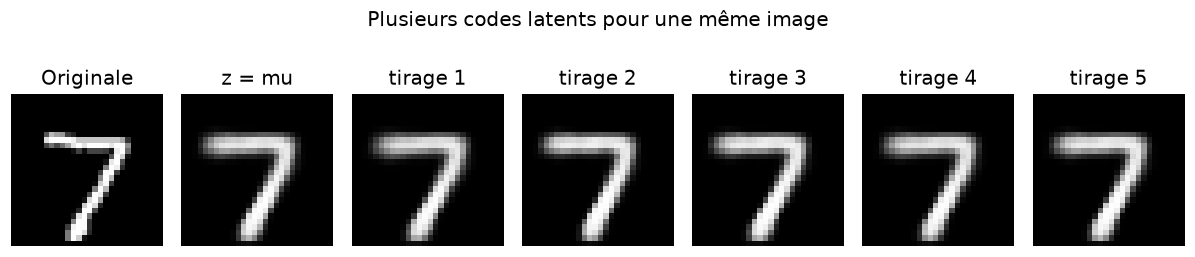

Écart-type latent moyen sur cette image : 0.0941
La loi conditionnelle est concentrée : les tirages restent visuellement proches de mu.


In [20]:
vae.eval()
demo = fixed_images[0:1].to(device)
with torch.no_grad():
    mu_demo, logvar_demo = vae.encode(demo)
    std_demo = torch.exp(0.5 * logvar_demo)
    recon_mu = vae.decode(mu_demo).cpu()
    torch.manual_seed(0)
    samples = [vae.decode(vae.reparameterize(mu_demo, logvar_demo)).cpu() for _ in range(5)]

print("Image de démonstration, chiffre", fixed_labels[0])
print("mu  =", mu_demo.detach().cpu().numpy())
print("std =", std_demo.detach().cpu().numpy())

fig, axes = plt.subplots(1, 7, figsize=(11, 2.2))
axes[0].imshow(fixed_images[0].squeeze(), cmap="gray", vmin=0, vmax=1)
axes[0].set_title("Originale")
axes[1].imshow(recon_mu[0, 0], cmap="gray", vmin=0, vmax=1)
axes[1].set_title("z = mu")
for index, sample in enumerate(samples, start=2):
    axes[index].imshow(sample[0, 0], cmap="gray", vmin=0, vmax=1)
    axes[index].set_title(f"tirage {index - 1}")
for axis in axes:
    axis.axis("off")
fig.suptitle("Plusieurs codes latents pour une même image", y=1.08)
fig.tight_layout()
save_figure(fig, "vae/reparametrisation.png")
plt.show()
plt.close(fig)

std_mean = float(std_demo.mean())
print(f"Écart-type latent moyen sur cette image : {std_mean:.4f}")
if std_mean < 0.15:
    print("La loi conditionnelle est concentrée : les tirages restent visuellement proches de mu.")
else:
    print("Les tirages s'écartent de mu. Deux appels à forward peuvent donc reconstruire deux variantes.")

### Reconstructions comparables à l'autoencodeur

`forward` tire normalement un échantillon. Pour comparer les modèles sur les mêmes dix images, la reconstruction principale utilise le code déterministe \(z = \mu\). C'est la moyenne de la loi latente, pas un tirage particulier.

Figure enregistrée : C:\Users\amald\Desktop\TP_ai_générative_N2\results\vae\reconstructions_vae.png


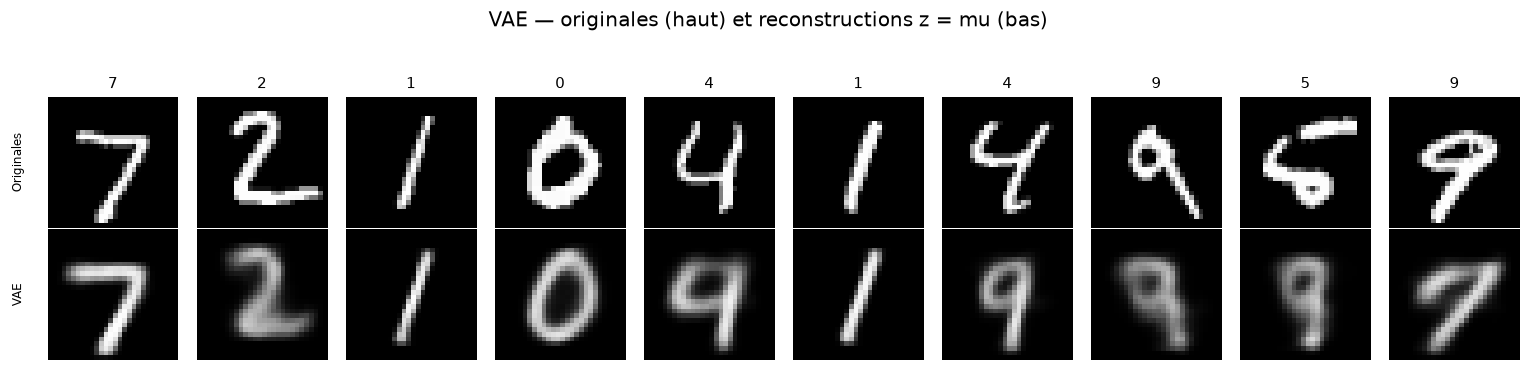

In [21]:
vae.eval()
with torch.no_grad():
    mu_fixed, _ = vae.encode(fixed_images.to(device))
    fixed_vae = vae.decode(mu_fixed).cpu()

assert fixed_vae.shape == (10, 1, 28, 28)
assert float(fixed_vae.min()) >= 0.0 and float(fixed_vae.max()) <= 1.0

fig, axes = plt.subplots(2, 10, figsize=(14, 3.2))
for i in range(10):
    axes[0, i].imshow(fixed_images[i].squeeze(), cmap="gray", vmin=0, vmax=1)
    axes[0, i].set_title(str(fixed_labels[i]), fontsize=10)
    axes[0, i].axis("off")
    axes[1, i].imshow(fixed_vae[i].squeeze(), cmap="gray", vmin=0, vmax=1)
    axes[1, i].axis("off")
label_row(axes[0, 0], "Originales")
label_row(axes[1, 0], "VAE")
fig.suptitle("VAE — originales (haut) et reconstructions z = mu (bas)", y=1.05)
fig.tight_layout()
save_figure(fig, "vae/reconstructions_vae.png")
plt.show()
plt.close(fig)

Les reconstructions du VAE sont en général plus lisses que les originaux. Le terme KL empêche l'encodeur d'utiliser des codes arbitrairement précis, et la dimension 2 limite ce qui peut être conservé. On juge ici la lisibilité du chiffre, pas seulement la valeur de la perte : une BCE plus faible n'est pas, à elle seule, une MSE, et elle n'est pas directement comparable à l'erreur de l'autoencodeur.

### Espace latent du VAE

Chaque image de test est représentée par la moyenne \(\mu = (\mu_1, \mu_2)\) de sa loi latente. La couleur est encore le chiffre réel, utilisé seulement pour la lecture.

Figure enregistrée : C:\Users\amald\Desktop\TP_ai_générative_N2\results\vae\espace_latent_vae.png


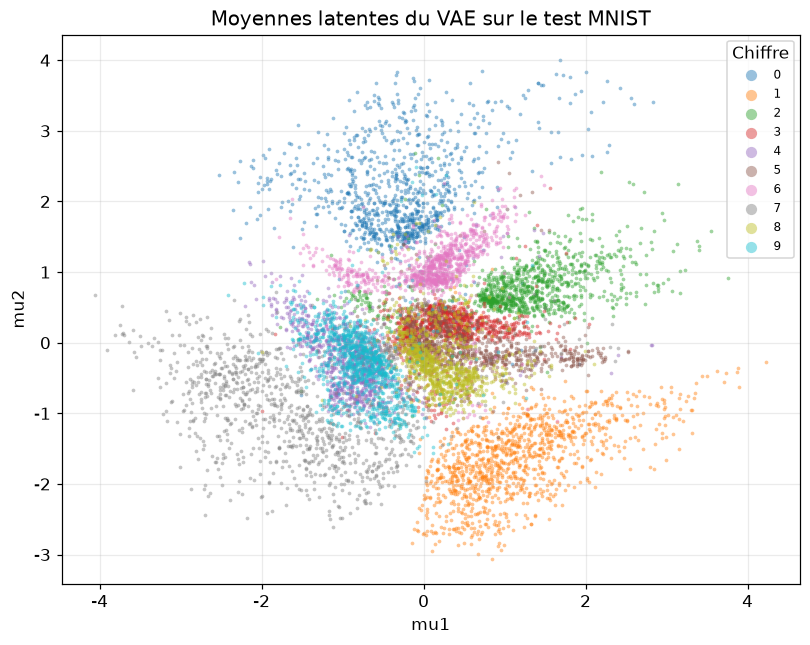

Score de silhouette du VAE : 0.1023
Score de silhouette de l'autoencodeur : -0.0078


In [22]:
@torch.no_grad()
def collect_vae_means(model, loader):
    model.eval()
    means = []
    labels = []
    for x, y in loader:
        mu, _ = model.encode(x.to(device))
        means.append(mu.cpu())
        labels.append(y)
    return torch.cat(means).numpy(), torch.cat(labels).numpy()


Z_vae, Y_vae = collect_vae_means(vae, test_loader)
assert Z_vae.shape == (10_000, 2)
silhouette_vae = float(silhouette_score(Z_vae, Y_vae))

fig, ax = plt.subplots(figsize=(7.5, 6))
cmap = plt.get_cmap("tab10")
for digit in range(10):
    mask = Y_vae == digit
    ax.scatter(
        Z_vae[mask, 0],
        Z_vae[mask, 1],
        s=6,
        alpha=0.45,
        color=cmap(digit),
        label=str(digit),
        linewidths=0,
    )
ax.set_xlabel("mu1")
ax.set_ylabel("mu2")
ax.set_title("Moyennes latentes du VAE sur le test MNIST")
ax.legend(title="Chiffre", markerscale=3, fontsize=8)
ax.grid(True, alpha=0.25)
fig.tight_layout()
save_figure(fig, "vae/espace_latent_vae.png")
plt.show()
plt.close(fig)
print(f"Score de silhouette du VAE : {silhouette_vae:.4f}")
print(f"Score de silhouette de l'autoencodeur : {silhouette_ae:.4f}")

La différence avec l'autoencodeur n'est pas seulement visuelle. Le nuage de l'autoencodeur peut s'étendre sur une échelle quelconque, parce que aucune perte ne fixe sa dispersion. Le nuage du VAE est tiré vers l'origine et vers une variance proche de 1 par la KL. Les groupes de chiffres peuvent donc sembler plus compacts, parfois plus mélangés : c'est le prix de la régularisation qui rendra le décodage d'un bruit gaussien possible. Un score de silhouette plus élevé indique des groupes plus séparés dans le plan. Il ne mesure pas la qualité des images générées.

### Génération de nouvelles images

Vingt vecteurs sont tirés dans le prior, sans passer par l'encodeur et sans étiquette :

```python
z = torch.randn(20, 2)
images = vae.decode(z)
```

C'est une génération **non conditionnelle**. Le modèle ne reçoit pas l'ordre de dessiner un 3 plutôt qu'un 8. La lisibilité se juge sur la figure : un échantillon flou ou ambigu reste un résultat du modèle, pas une réussite à déclarer par avance.

Figure enregistrée : C:\Users\amald\Desktop\TP_ai_générative_N2\results\vae\images_generees.png


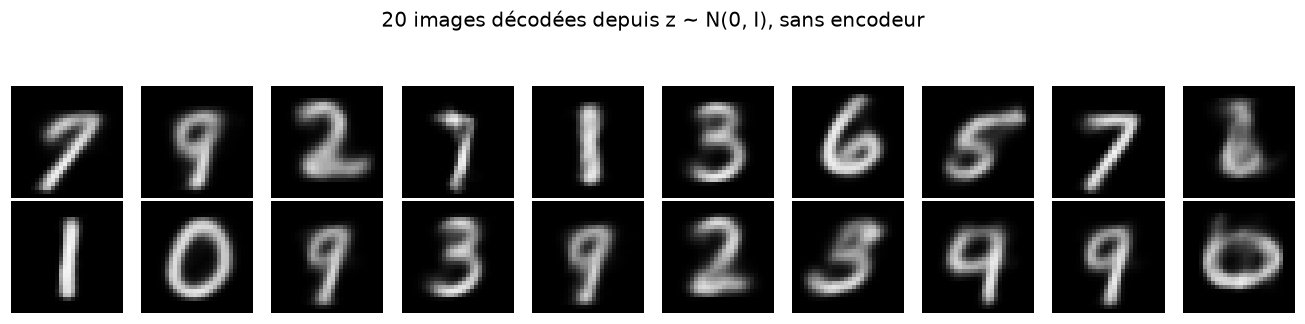

Aucune image MNIST n'a été présentée à l'encodeur. Seul le décodeur est utilisé. Le prior N(0, I) remplace le code d'une image réelle.


In [23]:
sampling_generator = torch.Generator()
sampling_generator.manual_seed(0)
z_new = torch.randn(20, LATENT_DIM, generator=sampling_generator).to(device)

vae.eval()
with torch.no_grad():
    generated = vae.decode(z_new).cpu()

assert generated.shape == (20, 1, 28, 28)
assert float(generated.min()) >= 0.0 and float(generated.max()) <= 1.0

fig, axes = plt.subplots(2, 10, figsize=(12, 2.8))
for i, axis in enumerate(axes.flat):
    axis.imshow(generated[i, 0], cmap="gray", vmin=0, vmax=1)
    axis.axis("off")
fig.suptitle("20 images décodées depuis z ~ N(0, I), sans encodeur", y=1.05)
fig.tight_layout()
save_figure(fig, "vae/images_generees.png")
plt.show()
plt.close(fig)
print(
    "Aucune image MNIST n'a été présentée à l'encodeur. "
    "Seul le décodeur est utilisé. Le prior N(0, I) remplace le code d'une image réelle."
)

### Exploration continue

La grille du cours place 15 valeurs de \(z_1\) et 15 valeurs de \(z_2\) entre \(-3\) et \(3\), soit **225** positions. Chaque position est décodée. Comme `imshow` met la première ligne en haut, le haut de la figure correspond à \(z_2 = -3\) et le bas à \(z_2 = 3\). De gauche à droite, \(z_1\) va de \(-3\) à \(3\).

Un petit déplacement dans le plan change peu le vecteur, donc peu l'image : les formes évoluent progressivement. Certaines zones, loin des codes réellement utilisés ou entre deux chiffres, produisent des formes peu reconnaissables. La dimension 2 rend cette carte possible. En dimension 32, la même exploration serait impossible à dessiner ainsi.

Figure enregistrée : C:\Users\amald\Desktop\TP_ai_générative_N2\results\vae\grille_latente.png


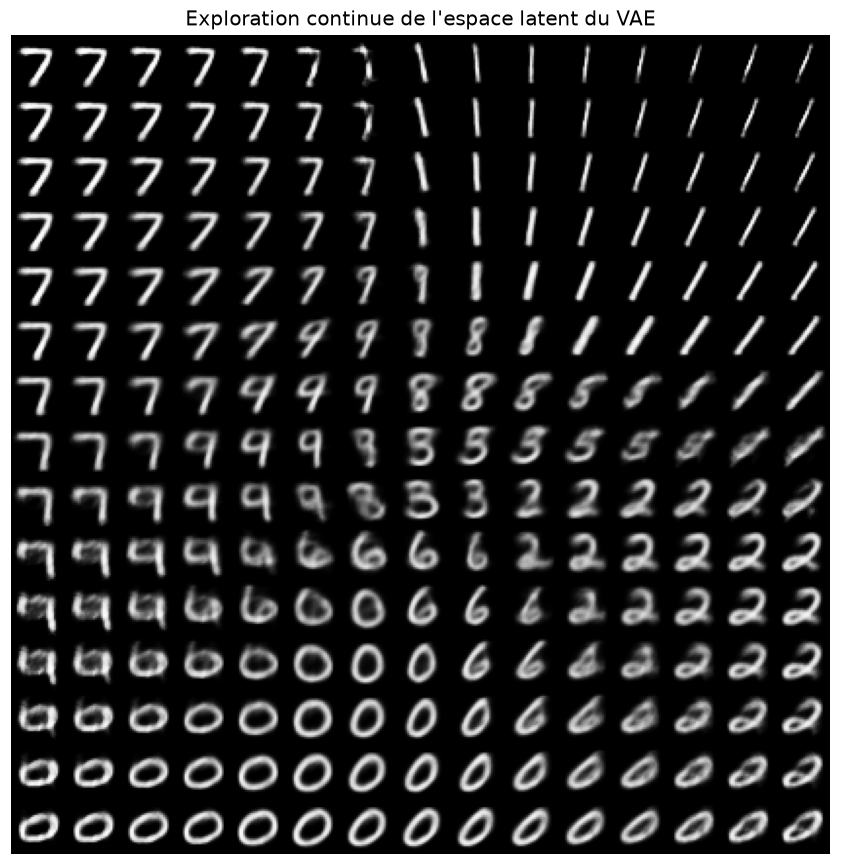

In [24]:
grid_x = np.linspace(-3, 3, 15)
grid_y = np.linspace(-3, 3, 15)
assert grid_x.size * grid_y.size == 225

figure = np.zeros((28 * 15, 28 * 15))
n_positions = 0
vae.eval()
with torch.no_grad():
    for i, yi in enumerate(grid_y):
        for j, xi in enumerate(grid_x):
            z = torch.tensor([[xi, yi]], dtype=torch.float32, device=device)
            x_hat = vae.decode(z)
            digit = x_hat.cpu().numpy()[0, 0]
            figure[i * 28:(i + 1) * 28, j * 28:(j + 1) * 28] = digit
            n_positions += 1

assert n_positions == 225
assert figure.shape == (28 * 15, 28 * 15)
assert float(figure.min()) >= 0.0 and float(figure.max()) <= 1.0

fig, ax = plt.subplots(figsize=(8, 8))
ax.imshow(figure, cmap="gray", vmin=0, vmax=1)
ax.set_title("Exploration continue de l'espace latent du VAE")
ax.axis("off")
fig.tight_layout()
save_figure(fig, "vae/grille_latente.png")
plt.show()
plt.close(fig)

### Interpolation entre deux chiffres

Cette expérience est un complément pédagogique. Elle n'est pas une consigne séparée du support, mais elle rend concret le déplacement dans l'espace latent.

On prend la première image de test étiquetée 1 et la première étiquetée 8. Leurs moyennes latentes sont reliées par dix positions

$$
z(\alpha) = (1 - \alpha)\,\mu^{(1)} + \alpha\,\mu^{(8)}, \qquad \alpha \in [0, 1].
$$

Chaque \(z(\alpha)\) est décodé. Les extrémités sont les reconstructions \(z = \mu\) des deux images, pas les pixels originaux. Une interpolation latente est un segment dans le code, pas un fondu pixel à pixel.

Figure enregistrée : C:\Users\amald\Desktop\TP_ai_générative_N2\results\vae\interpolation.png


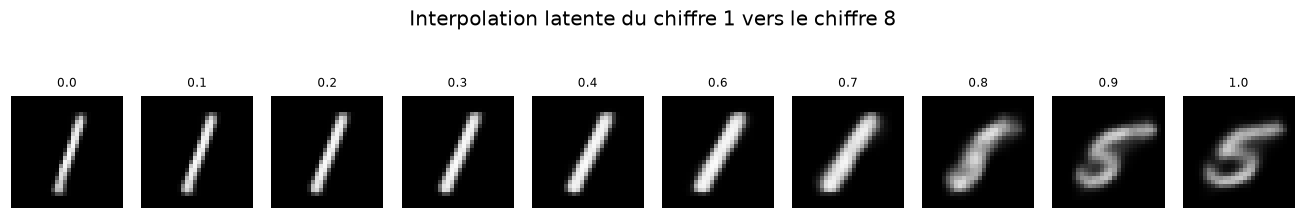

In [25]:
def first_index_of_digit(dataset, digit):
    for index, (_, label) in enumerate(dataset):
        if int(label) == digit:
            return index
    raise RuntimeError(f"Chiffre {digit} introuvable.")


index_one = first_index_of_digit(test_dataset, 1)
index_eight = first_index_of_digit(test_dataset, 8)
image_one = test_dataset[index_one][0].unsqueeze(0).to(device)
image_eight = test_dataset[index_eight][0].unsqueeze(0).to(device)

vae.eval()
with torch.no_grad():
    mu_one, _ = vae.encode(image_one)
    mu_eight, _ = vae.encode(image_eight)
    interpolated = []
    for alpha in np.linspace(0.0, 1.0, 10):
        z_alpha = (1.0 - alpha) * mu_one + alpha * mu_eight
        interpolated.append(vae.decode(z_alpha).cpu())

fig, axes = plt.subplots(1, 10, figsize=(12, 1.8))
for axis, alpha, image in zip(axes, np.linspace(0.0, 1.0, 10), interpolated):
    axis.imshow(image[0, 0], cmap="gray", vmin=0, vmax=1)
    axis.set_title(f"{alpha:.1f}", fontsize=8)
    axis.axis("off")
fig.suptitle("Interpolation latente du chiffre 1 vers le chiffre 8", y=1.12)
fig.tight_layout()
save_figure(fig, "vae/interpolation.png")
plt.show()
plt.close(fig)

In [26]:
vae_path = MODELS_DIR / "vae_mnist.pth"
torch.save(vae.state_dict(), vae_path)

reloaded_vae = VAE(latent_dim=LATENT_DIM).to(device)
reloaded_vae.load_state_dict(torch.load(vae_path, map_location=device, weights_only=True))
reloaded_vae.eval()
vae.eval()
with torch.no_grad():
    mu_a, logvar_a = vae.encode(check_x)
    mu_b, logvar_b = reloaded_vae.encode(check_x)
    recon_a = vae.decode(mu_a)
    recon_b = reloaded_vae.decode(mu_b)
assert torch.allclose(mu_a, mu_b, atol=1e-5)
assert torch.allclose(logvar_a, logvar_b, atol=1e-5)
assert torch.allclose(recon_a, recon_b, atol=1e-5)
print("Sauvegarde vérifiée :", vae_path)
print("Le contrôle utilise encode et decode(mu), parce que forward tire un bruit différent à chaque appel.")

Sauvegarde vérifiée : C:\Users\amald\Desktop\TP_ai_générative_N2\models\vae_mnist.pth
Le contrôle utilise encode et decode(mu), parce que forward tire un bruit différent à chaque appel.


## 7. Comparaison des modèles

| Critère | Classifier | Autoencoder | VAE |
|---|---|---|---|
| Type de modèle | Discriminatif | Génératif, orienté reconstruction | Génératif probabiliste |
| Objectif | Prédire le chiffre | Reconstruire l'image | Reconstruire et pouvoir échantillonner |
| Entrée | Image 1 × 28 × 28 | Image 1 × 28 × 28 | Image à l'entraînement, ou \(z\) à la génération |
| Sortie | 10 logits | Image 1 × 28 × 28 | Image, \(\mu\), `logvar` |
| Fonction de perte | Entropie croisée | MSE | BCE + \(\beta\) KL, \(\beta = 1\) |
| Espace latent | Aucun | Déterministe, dimension 2 | Gaussien, dimension 2 |
| Génération autonome | Non | Non fiable, espace non régularisé | Oui, \(z \sim \mathcal{N}(0, I)\) puis décodeur |
| Nombre d'époques | 3 | 5 | 20 |

Les mesures de la cellule suivante proviennent de cette exécution. **La MSE et la BCE ne sont pas comparables** : elles n'ont ni la même formule, ni la même échelle. Une BCE d'environ 140 par image n'est pas « pire » qu'une MSE de 0,05 par pixel. Pour comparer les reconstructions sur une échelle commune, la cellule calcule aussi une MSE par pixel pour les deux modèles, avec \(z = \mu\) pour le VAE.

Figure enregistrée : C:\Users\amald\Desktop\TP_ai_générative_N2\results\comparaison_ae_vae.png


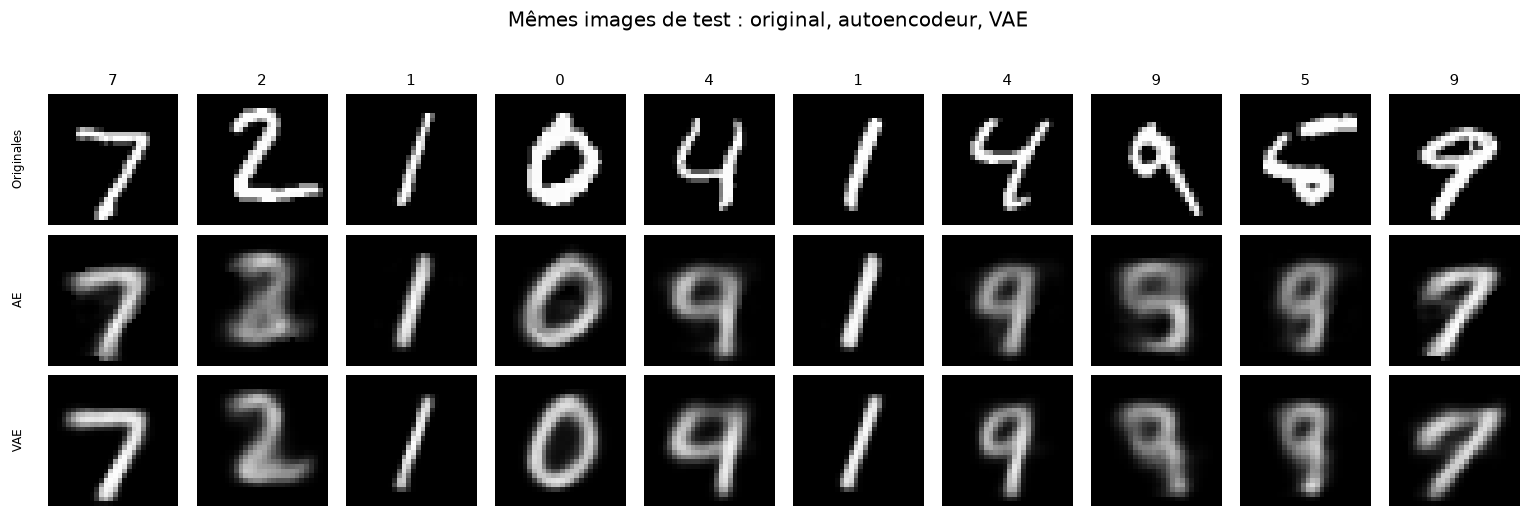

,Mesure,Valeur observée
0,Accuracy du classifieur,96.31 %
1,Images correctement classées,9631 / 10000
2,Images mal classées,369 / 10000
3,Précision / rappel / F1 macro,0.9629 / 0.9627 / 0.9628
4,"MSE de reconstruction de l'AE, par pixel",0.0432
5,MSE par pixel du VAE avec z = mu,0.0374
6,"BCE de reconstruction du VAE, par image",135.73
7,"Divergence KL du VAE, par image",6.51
8,Époques exécutées,"classifieur 3, AE 5, VAE 20"



| Mesure | Valeur observée |
|---|---|
| Accuracy du classifieur | 96.31 % |
| Images correctement classées | 9631 / 10000 |
| Images mal classées | 369 / 10000 |
| Précision / rappel / F1 macro | 0.9629 / 0.9627 / 0.9628 |
| MSE de reconstruction de l'AE, par pixel | 0.0432 |
| MSE par pixel du VAE avec z = mu | 0.0374 |
| BCE de reconstruction du VAE, par image | 135.73 |
| Divergence KL du VAE, par image | 6.51 |
| Époques exécutées | classifieur 3, AE 5, VAE 20 |


Sur la MSE par pixel, le VAE est plus proche des images de test (AE = 0.0432, VAE = 0.0374).
Ce constat ne désigne pas un modèle supérieur dans l'absolu. L'autoencodeur optimise directement cette MSE. Le VAE optimise une BCE et une KL : il dépense une partie de sa capacité à organiser l'espace latent. La figure montre, chiffre par chiffre, ce que chaque reconstruction conserve.
Séparation des codes sur le test, score de silhouette : AE = -0.0078, VAE = 0.1023.


In [27]:
@torch.no_grad()
def pixel_mse(reconstruct, loader):
    total = 0.0
    n_values = 0
    for x, _ in loader:
        x = x.to(device)
        x_hat = reconstruct(x)
        total += F.mse_loss(x_hat, x, reduction="sum").item()
        n_values += x.numel()
    mse = total / n_values
    assert math.isfinite(mse)
    return mse


ae.eval()
vae.eval()
mse_ae_pixels = pixel_mse(lambda batch: ae(batch), test_loader)
mse_vae_pixels = pixel_mse(
    lambda batch: vae.decode(vae.encode(batch)[0]),
    test_loader,
)
assert abs(mse_ae_pixels - ae_test_mse) < 1e-8

fig, axes = plt.subplots(3, 10, figsize=(14, 4.6))
rows = (
    (fixed_images, "Originales"),
    (fixed_ae, "AE"),
    (fixed_vae, "VAE"),
)
for row, (images_row, title) in enumerate(rows):
    for column in range(10):
        axes[row, column].imshow(images_row[column].squeeze(), cmap="gray", vmin=0, vmax=1)
        axes[row, column].axis("off")
        if row == 0:
            axes[row, column].set_title(str(fixed_labels[column]), fontsize=10)
    label_row(axes[row, 0], title)
fig.suptitle("Mêmes images de test : original, autoencodeur, VAE", y=1.02)
fig.tight_layout()
save_figure(fig, "comparaison_ae_vae.png")
plt.show()
plt.close(fig)

if mse_vae_pixels < mse_ae_pixels:
    lower_mse_model = "le VAE"
else:
    lower_mse_model = "l'autoencodeur classique"

from IPython.display import Markdown, display

metrics_table = pd.DataFrame(
    [
        ["Accuracy du classifieur", f"{100 * classifier_metrics['accuracy']:.2f} %"],
        ["Images correctement classées", f"{classifier_metrics['correct']} / 10000"],
        ["Images mal classées", f"{classifier_metrics['incorrect']} / 10000"],
        [
            "Précision / rappel / F1 macro",
            (
                f"{classifier_metrics['precision_macro']:.4f} / "
                f"{classifier_metrics['recall_macro']:.4f} / "
                f"{classifier_metrics['f1_macro']:.4f}"
            ),
        ],
        ["MSE de reconstruction de l'AE, par pixel", f"{ae_test_mse:.4f}"],
        ["MSE par pixel du VAE avec z = mu", f"{mse_vae_pixels:.4f}"],
        ["BCE de reconstruction du VAE, par image", f"{vae_test['rec']:.2f}"],
        ["Divergence KL du VAE, par image", f"{vae_test['kl']:.2f}"],
        [
            "Époques exécutées",
            f"classifieur {EPOCHS_CLASSIFIER}, AE {EPOCHS_AUTOENCODER}, VAE {EPOCHS_VAE}",
        ],
    ],
    columns=["Mesure", "Valeur observée"],
)
metrics_table.to_csv(RESULTS_DIR / "comparaison_metriques.csv", index=False, encoding="utf-8")
display(metrics_table)

display(Markdown(
    f"""
| Mesure | Valeur observée |
|---|---|
| Accuracy du classifieur | {100 * classifier_metrics['accuracy']:.2f} % |
| Images correctement classées | {classifier_metrics['correct']} / 10000 |
| Images mal classées | {classifier_metrics['incorrect']} / 10000 |
| Précision / rappel / F1 macro | {classifier_metrics['precision_macro']:.4f} / {classifier_metrics['recall_macro']:.4f} / {classifier_metrics['f1_macro']:.4f} |
| MSE de reconstruction de l'AE, par pixel | {ae_test_mse:.4f} |
| MSE par pixel du VAE avec z = mu | {mse_vae_pixels:.4f} |
| BCE de reconstruction du VAE, par image | {vae_test['rec']:.2f} |
| Divergence KL du VAE, par image | {vae_test['kl']:.2f} |
| Époques exécutées | classifieur {EPOCHS_CLASSIFIER}, AE {EPOCHS_AUTOENCODER}, VAE {EPOCHS_VAE} |
"""
))
print(
    f"Sur la MSE par pixel, {lower_mse_model} est plus proche des images de test "
    f"(AE = {mse_ae_pixels:.4f}, VAE = {mse_vae_pixels:.4f})."
)
print(
    "Ce constat ne désigne pas un modèle supérieur dans l'absolu. "
    "L'autoencodeur optimise directement cette MSE. "
    "Le VAE optimise une BCE et une KL : il dépense une partie de sa capacité à organiser l'espace latent. "
    "La figure montre, chiffre par chiffre, ce que chaque reconstruction conserve."
)
print(
    f"Séparation des codes sur le test, score de silhouette : "
    f"AE = {silhouette_ae:.4f}, VAE = {silhouette_vae:.4f}."
)

## Questions de compréhension

**1. Quelle est la différence entre IA discriminative et IA générative ?**

L'IA discriminative apprend à prédire une cible à partir d'une observation, ici \(P(y \mid x)\) : le chiffre sachant l'image. L'IA générative modélise la distribution des observations elles-mêmes, \(P(x)\) ou \(P(x, z)\), ce qui permet de reconstruire et, si le modèle est probabiliste, de créer de nouveaux exemples.

**2. Pourquoi un modèle discriminatif ne génère-t-il pas directement une image ?**

Le classifieur de ce TP sort dix logits. Sa perte compare ces scores à une étiquette. Aucune couche ne recompose des pixels, et aucun exemple de sortie n'est une image. Il peut dire « ceci ressemble à un 4 ». Il ne peut pas dessiner un 4.

**3. Quel est le rôle de l'encodeur ?**

L'encodeur compresse l'image. Dans l'autoencodeur, il produit un code \(z\). Dans le VAE, il produit les paramètres \(\mu\) et `logvar` de la loi de ce code.

**4. Quel est le rôle du décodeur ?**

Le décodeur transforme un code latent en image de 28 × 28. Il sert à la reconstruction quand le code vient d'une image réelle, et à la génération quand le code est tiré dans le prior.

**5. Qu'est-ce qu'un espace latent ?**

C'est l'espace des codes \(z\). Chaque image y est résumée par quelques coordonnées. La proximité de deux points traduit une proximité selon les caractéristiques que le modèle a apprises, pas nécessairement selon les pixels bruts.

**6. Pourquoi choisir `latent_dim = 2` ?**

Deux coordonnées se dessinent dans un plan. On peut ainsi voir les groupes, les chevauchements, la grille et l'interpolation. Le coût est une forte perte d'information : deux nombres ne suffisent pas à conserver tous les détails d'un manuscrit.

**7. Quelle est la fonction de perte de l'AE ?**

L'erreur quadratique moyenne entre l'image originale et l'image reconstruite, `nn.MSELoss()`. Les étiquettes n'interviennent pas.

**8. Pourquoi le VAE utilise-t-il deux sorties `mu` et `logvar` ?**

Parce qu'il décrit une gaussienne, pas un point. `mu` place le centre de la loi. `logvar` fixe sa dispersion, sous une forme qui reste stable à entraîner et qui donne une variance positive après exponentielle.

**9. Qu'est-ce que la reparamétrisation ?**

C'est l'écriture \(z = \mu + \sigma \odot \epsilon\), avec \(\epsilon \sim \mathcal{N}(0, I)\). Elle sépare le tirage aléatoire des paramètres du réseau, ce qui permet de rétropropager la perte jusqu'à l'encodeur.

**10. Quel est le rôle de la divergence KL ?**

Elle mesure l'écart entre la loi proposée par l'encodeur et le prior \(\mathcal{N}(0, I)\). La minimiser rapproche les codes d'une loi connue, continue et facile à échantillonner. Elle régularise l'espace latent.

**11. Quelle est la différence entre reconstruire et générer ?**

Reconstruire part d'une image réelle : on l'encode, puis on la décode. Générer part d'un code choisi sans image, ici un tirage du prior, et seul le décodeur est utilisé.

**12. Pourquoi le VAE peut-il générer à partir d'un bruit gaussien ?**

Pendant l'entraînement, la KL pousse \(q(z \mid x)\) vers \(\mathcal{N}(0, I)\). Le décodeur apprend donc à transformer des codes de cette région en images. Au moment de la génération, on tire directement \(z \sim \mathcal{N}(0, I)\) et on le décode. C'est un échantillonnage ancestral du modèle, non conditionné par un chiffre.

**13. Quelle différence existe-t-il entre AE et VAE ?**

L'autoencodeur produit un code déterministe et minimise une MSE. Le VAE produit une loi, tire un code par reparamétrisation, et minimise une BCE plus une KL. Leurs réseaux diffèrent aussi : 784-128-32-2 d'un côté, 784-256-64 puis deux têtes vers 2 de l'autre. Seul le VAE est conçu pour qu'un bruit gaussien standard soit un code acceptable.

**14. Que représente un point dans la visualisation latente ?**

Un point est le code d'une image de test : \(z\) pour l'autoencodeur, \(\mu\) pour le VAE. La couleur est le chiffre réel. Elle aide la lecture, mais elle n'a pas été donnée au modèle pendant l'apprentissage de ces deux réseaux.

**15. Pourquoi une représentation latente peut-elle être utile au-delà de la reconstruction ?**

Le code est un résumé compact. On peut le visualiser, interpoler entre deux images, compresser, détecter un exemple atypique loin des groupes, ou l'utiliser comme entrée d'un autre algorithme. La grille du VAE montre en plus qu'un déplacement continu dans ce résumé produit une transformation continue de l'image.

## 8. Conclusion générale

Le **classifieur** est un modèle discriminatif. Il reçoit une image et renvoie des scores de classes. Il apprend \(P(y \mid x)\). Il reconnaît un chiffre déjà dessiné. Il ne le dessine pas.

L'**autoencodeur** apprend une reconstruction. L'encodeur résume l'image par deux nombres, le décodeur tente de retrouver les pixels. La perte est une MSE. Le résultat utile est un code et une image reconstruite, pas une procédure fiable pour inventer un manuscrit : l'espace latent n'est pas rattaché à une loi de probabilité.

Le **VAE** ajoute cette loi. L'encodeur fournit \(\mu\) et `logvar`, un bruit gaussien est reparamétré en code \(z\), et le décodeur reconstruit l'image. La BCE demande une reconstruction fidèle. La KL demande que les codes restent compatibles avec \(\mathcal{N}(0, I)\). Cette seconde contrainte est ce qui autorise la génération, la grille et l'interpolation.

La classification, la reconstruction et la génération répondent donc à trois questions distinctes : quelle est la classe, comment retrouver l'image à partir d'un résumé, comment proposer une image nouvelle. L'espace latent est l'outil commun des deux derniers modèles. En deux dimensions, il se regarde. Il oublie aussi beaucoup de détails.

Les valeurs numériques de cette exécution, le périphérique utilisé et les fichiers produits sont rassemblés par la cellule suivante. Les limites principales sont connues dès le choix du support : réseaux entièrement connectés, espace latent de dimension 2, 3, 5 et 20 époques, génération non conditionnelle, et pixels modélisés indépendamment. Une dimension latente plus grande, un encodeur convolutif ou un modèle conditionné par l'étiquette amélioreraient la finesse des images. Les GAN et les modèles de diffusion, présents plus loin dans le notebook du cours, abordent la génération par d'autres principes. Ils ne font pas partie de cette première partie.

In [28]:
assert (MODELS_DIR / "classifier_mnist.pth").is_file()
assert (MODELS_DIR / "autoencoder_mnist.pth").is_file()
assert (MODELS_DIR / "vae_mnist.pth").is_file()
for relative in (
    "mnist_exemples.png",
    "classifier/courbe_perte.png",
    "classifier/matrice_confusion.png",
    "classifier/predictions.png",
    "autoencoder/courbe_perte.png",
    "autoencoder/reconstructions.png",
    "autoencoder/espace_latent.png",
    "autoencoder/chiffres_moyens.png",
    "autoencoder/echantillons_aleatoires.png",
    "vae/loss_vae.png",
    "vae/reparametrisation.png",
    "vae/reconstructions_vae.png",
    "vae/espace_latent_vae.png",
    "vae/images_generees.png",
    "vae/grille_latente.png",
    "vae/interpolation.png",
    "comparaison_ae_vae.png",
    "comparaison_metriques.csv",
):
    assert (RESULTS_DIR / relative).is_file(), relative

metrics = {
    "device": str(device),
    "torch": torch.__version__,
    "torchvision": torchvision.__version__,
    "epochs_classifieur": EPOCHS_CLASSIFIER,
    "epochs_autoencodeur": EPOCHS_AUTOENCODER,
    "epochs_vae": EPOCHS_VAE,
    "beta": BETA,
    "accuracy_classifieur": classifier_metrics["accuracy"],
    "images_correctes": classifier_metrics["correct"],
    "images_incorrectes": classifier_metrics["incorrect"],
    "precision_macro": classifier_metrics["precision_macro"],
    "recall_macro": classifier_metrics["recall_macro"],
    "f1_macro": classifier_metrics["f1_macro"],
    "mse_test_autoencodeur": ae_test_mse,
    "mse_pixels_vae_mu": mse_vae_pixels,
    "vae_test_loss_par_image": vae_test["loss"],
    "vae_test_reconstruction_bce_par_image": vae_test["rec"],
    "vae_test_kl_par_image": vae_test["kl"],
    "silhouette_ae": silhouette_ae,
    "silhouette_vae": silhouette_vae,
    "perte_finale_classifieur": classifier_history[-1],
    "perte_finale_autoencodeur": ae_history[-1],
    "perte_finale_vae": vae_loss_history[-1],
    "bce_finale_vae": vae_rec_history[-1],
    "kl_finale_vae": vae_kl_history[-1],
}
metrics_path = RESULTS_DIR / "metriques.json"
metrics_path.write_text(json.dumps(metrics, indent=2, ensure_ascii=False), encoding="utf-8")

print("RESULTATS_REELS")
for key, value in metrics.items():
    if isinstance(value, float):
        print(f"{key}={value:.6f}")
    else:
        print(f"{key}={value}")
print("Fichier :", metrics_path)
print(
    f"Observé sur {device} : le classifieur atteint {100 * metrics['accuracy_classifieur']:.2f} % "
    f"en {EPOCHS_CLASSIFIER} époques ; l'autoencodeur termine à une MSE test de "
    f"{metrics['mse_test_autoencodeur']:.4f} par pixel en {EPOCHS_AUTOENCODER} époques ; "
    f"le VAE, après {EPOCHS_VAE} époques, a une BCE test de {metrics['vae_test_reconstruction_bce_par_image']:.2f} "
    f"et une KL test de {metrics['vae_test_kl_par_image']:.2f} par image."
)

RESULTATS_REELS
device=cpu
torch=2.15.0+cpu
torchvision=0.29.2+cpu
epochs_classifieur=3
epochs_autoencodeur=5
epochs_vae=20
beta=1.000000
accuracy_classifieur=0.963100
images_correctes=9631
images_incorrectes=369
precision_macro=0.962937
recall_macro=0.962667
f1_macro=0.962766
mse_test_autoencodeur=0.043196
mse_pixels_vae_mu=0.037386
vae_test_loss_par_image=142.239557
vae_test_reconstruction_bce_par_image=135.726038
vae_test_kl_par_image=6.513519
silhouette_ae=-0.007822
silhouette_vae=0.102255
perte_finale_classifieur=0.138896
perte_finale_autoencodeur=0.043633
perte_finale_vae=141.931135
bce_finale_vae=135.480927
kl_finale_vae=6.450208
Fichier : C:\Users\amald\Desktop\TP_ai_générative_N2\results\metriques.json
Observé sur cpu : le classifieur atteint 96.31 % en 3 époques ; l'autoencodeur termine à une MSE test de 0.0432 par pixel en 5 époques ; le VAE, après 20 époques, a une BCE test de 135.73 et une KL test de 6.51 par image.
